## 1. The data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lab

ENCODE_ON_GPU = False  # late interaction: False uses the downloaded token vectors; True encodes them again on your GPU

caiq, fiqa = lab.load("caiq"), lab.load("fiqa")
DATASETS = (caiq, fiqa)

In [2]:
for ds in DATASETS:
    words = [len(lab.tokenize(t)) for t in ds.texts]
    rel = [sum(g > 0 for g in q.values()) for q in ds.qrels.values()]
    print(f"{ds.name}: {len(ds.ids):,} documents, {len(ds.queries)} questions, "
          f"median document {np.median(words):.0f} words, {np.mean(rel):.1f} relevant documents per question")

caiq: 644 documents, 119 questions, median document 24 words, 9.7 relevant documents per question


fiqa: 57,912 documents, 648 questions, median document 95 words, 2.6 relevant documents per question


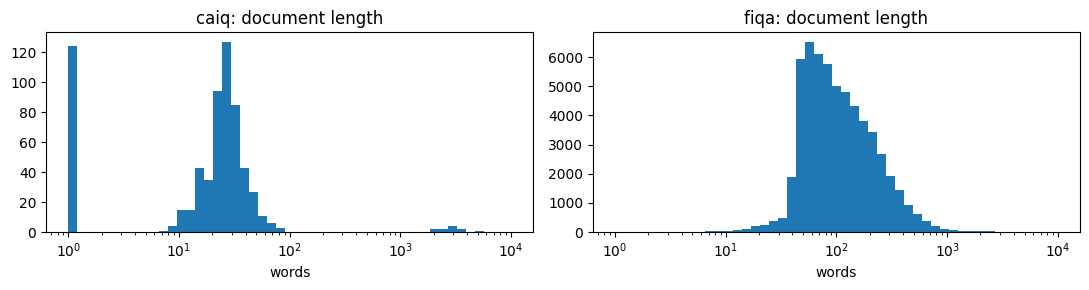

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    words = np.array([len(lab.tokenize(t)) for t in ds.texts])
    ax.hist(words, bins=np.logspace(0, 4, 50))
    ax.set_xscale("log")
    ax.set_title(f"{ds.name}: document length")
    ax.set_xlabel("words")
fig.tight_layout()

In [4]:
for ds in DATASETS:
    qid = next(iter(ds.queries))
    best = max(ds.qrels[qid], key=ds.qrels[qid].get)
    print(f"{ds.name} question: {ds.queries[qid]}")
    print(f"relevant (grade {ds.qrels[qid][best]}): {ds.titles[ds.row[best]]} {ds.texts[ds.row[best]][:300]}\n")

caiq question: For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained?
relevant (grade 1): Present SpA — A&A-06.1: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained? Yes. Performed as part of ISO 27001:2013 standard certification.

fiqa question: How to deposit a cheque issued to an associate in my business into my business account?
relevant (grade 1):  Have the check reissued to the proper payee.



## 2. From text to terms

In [5]:
for s in ("Is data-at-rest encrypted (AES-256)?", "Café naïve ﬁnance: 401(k) or IRA?", "TLS_1.2 vs. TLS-1.3"):
    print(f"{s!r:40} -> {lab.tokenize(s)}")

'Is data-at-rest encrypted (AES-256)?'   -> ['is', 'data', 'at', 'rest', 'encrypted', 'aes', '256']
'Café naïve ﬁnance: 401(k) or IRA?'      -> ['cafe', 'naive', 'finance', '401', 'k', 'or', 'ira']
'TLS_1.2 vs. TLS-1.3'                    -> ['tls', '1', '2', 'vs', 'tls', '1', '3']


In [6]:
STOP = lab.Analyzer(stopwords=True)  # tokens without stopwords
STEM = lab.Analyzer(stopwords=True, stemming=True)  # ... and each word reduced to its stem

words = lab.tokenize("Are encryption keys rotated and are encrypted backups stored offsite?")
print("tokens:   ", words)
print("stopwords:", [w for w in words if w in lab.STOPWORDS])
print("terms:    ", STEM.terms(" ".join(words))[0])

tokens:    ['are', 'encryption', 'keys', 'rotated', 'and', 'are', 'encrypted', 'backups', 'stored', 'offsite']
stopwords: ['are', 'and', 'are']
terms:     ['encrypt', 'key', 'rotat', 'encrypt', 'backup', 'store', 'offsit']


## 3. An inverted index

In [7]:
ix = lab.index(caiq.texts, STOP)
docs, tf = ix.postings("encryption")
print(f"encryption: in {len(docs)} of {ix.n} documents; postings (document, count): {list(zip(docs[:5].tolist(), tf[:5].astype(int).tolist()))} …")
keys = ix.occurrences("encryption")[:5]
print(f"occurrences (document, position): {[(int(k // lab.STRIDE), int(k % lab.STRIDE)) for k in keys]} …")

a, b = ix.postings("encryption")[0], ix.postings("keys")[0]
print(f"encryption AND keys: {len(np.intersect1d(a, b))} documents; encryption OR keys: {len(np.union1d(a, b))}")
docs, tf = ix.where([(0, "encryption"), (1, "keys")])  # "keys" one position after "encryption"
print(f'"encryption keys": {len(docs)} documents, {int(tf.sum())} times')

print(f"\n{'':20s}{'terms':>12s}{'occurrences':>14s}{'terms':>12s}{'occurrences':>14s}")
print(f"{'':20s}{'caiq':>26s}{'fiqa':>26s}")
for name, a in (("tokens", lab.TOKENS), ("without stopwords", STOP), ("stemmed", STEM)):
    print(f"{name:20s}" + "".join(f"{len(lab.index(ds.texts, a).vocab):12,d}{int(lab.index(ds.texts, a).lengths.sum()):14,d}" for ds in DATASETS))

encryption: in 53 of 644 documents; postings (document, count): [(22, 1), (159, 1), (162, 1), (163, 1), (165, 2)] …
occurrences (document, position): [(22, 22), (159, 24), (162, 5), (163, 12), (165, 3)] …
encryption AND keys: 10 documents; encryption OR keys: 55
"encryption keys": 8 documents, 10 times

                           terms   occurrences       terms   occurrences
                                          caiq                      fiqa


tokens                     1,831        47,491      77,486     8,271,209


without stopwords          1,777        42,407      77,422     4,938,427


stemmed                    1,290        42,407      56,913     4,938,427


## 4. Matching words

                      caiq               fiqa         
matching words       0.016              0.079         


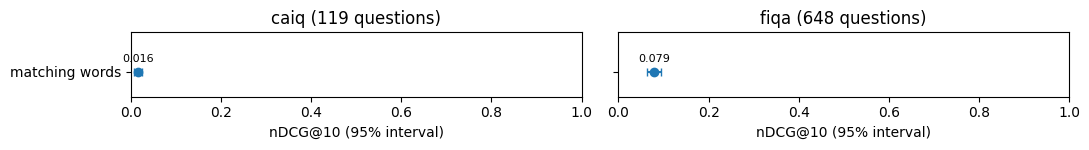

In [8]:
MATCH = {ds.name: lab.matching(ds, ds.texts) for ds in DATASETS}  # how many of the question's words each document has
runs = {ds.name: {"matching words": lab.evaluate(ds, MATCH[ds.name])} for ds in DATASETS}
lab.plot_ladder(runs);

In [9]:
lab.show(caiq, caiq.qids[0], {"matching words": MATCH["caiq"]})

q:fimil:A&A-06.1: For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained?

matching words  nDCG@10 0.000
  1. [.] misc:007       Untitled Yes. Yes. Audit logs stored in PostgreSQL with database-level access controls. Ad…
  2. [.] misc:009       Untitled NA. Cloud-hosted on DigitalOcean. Physical datacenter asset tracking is the cloud…
  3. [.] misc:001       Untitled Yes. Yes. The organization maintains incident response procedures as part of Info…
  4. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…
  5. [.] misc:000       Untitled Partial. People Security Policy defines endpoint security requirements. Technical…



## 5. Stopwords

fiqa: nDCG@10 0.079 before, 0.106 after; better 104, worse 53 of 648 questions; fixed 5, broken 0 (from below 0.3 to above 0.7, or back)

691: How to categorize credit card payments?



matching words  nDCG@10 0.000
  1. [.] 600066         "It makes no sense to spend money unnecessarily, just for the purpose of improving your cr…
  2. [.] 156873         "With the scenario that you laid out (ie. 5% and 10% loans), it makes no sense at all. The…
  3. [.] 249450         "Split transactions are indispensable to anybody interested in accurately tracking their s…
  4. [.] 486617         There's the fear that one might forget the debit is coming and still bounce the payment. P…
  5. [.] 481063         "It's been a short while since I sold on eBay, but I had a feedback rating of about 4,500 …



+ stopwords  nDCG@10 1.000
  1. [1] 395912         "Using the Transfer category is the best place to put these categories, as that accurately…
  2. [.] 143844         "There's a difference between missing a payment and ""carrying a balance"" (making an on-t…
  3. [.] 5953           The answer depends on how much you spend every month. The DTI is calculated using the mini…
  4. [.] 560251         I don't believe Saturday is a business day either. When I deposit a check at a bank's driv…
  5. [.] 147439         "This is not a full answer and I have no personal finance experience. But I have a persona…

                      caiq               fiqa         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)


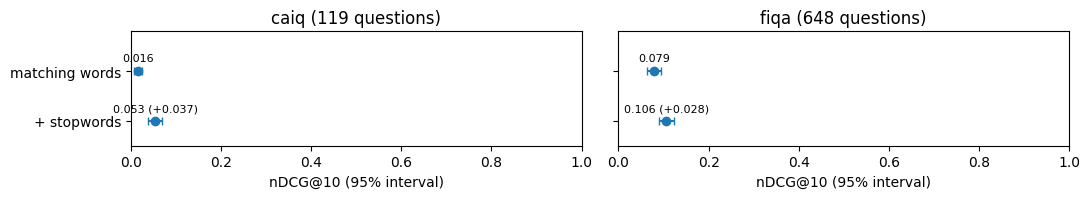

In [10]:
MATCH_STOP = {ds.name: lab.matching(ds, ds.texts, STOP) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["+ stopwords"] = lab.evaluate(ds, MATCH_STOP[ds.name])
example = lab.example(fiqa, runs["fiqa"]["matching words"], runs["fiqa"]["+ stopwords"])
lab.show(fiqa, example, {"matching words": MATCH["fiqa"], "+ stopwords": MATCH_STOP["fiqa"]})
lab.plot_ladder(runs);

## 6. TF-IDF

caiq: nDCG@10 0.053 before, 0.030 after; better 10, worse 44 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)

q:present:HRS-11.2: For Present SpA: Are regular security awareness training updates provided?

+ stopwords  nDCG@10 0.297
  1. [.] misc:007       Untitled Yes. Yes. Audit logs stored in PostgreSQL with database-level access controls. Ad…
  2. [1] present:HRS-11.1 Present SpA — HRS-11.1: Is a security awareness training program for all employees of the …
  3. [.] misc:003       Untitled NA. Yes. Automated quarterly access reviews via Fimil-Ops endpoints. API token au…
  4. [.] misc:005       Untitled Yes. Operator role is the highest privilege level (100). Impersonation limited to…
  5. [.] misc:006       Untitled Yes. Change Management Policy defines Emergency change type with expedited approv…

tf-idf  nDCG@10 0.145
  1. [.] misc:008       Untitled NA. Cloud-hosted on DigitalOcean. Physical hardware relocation is the cloud provi…
  2. [.] misc:005  

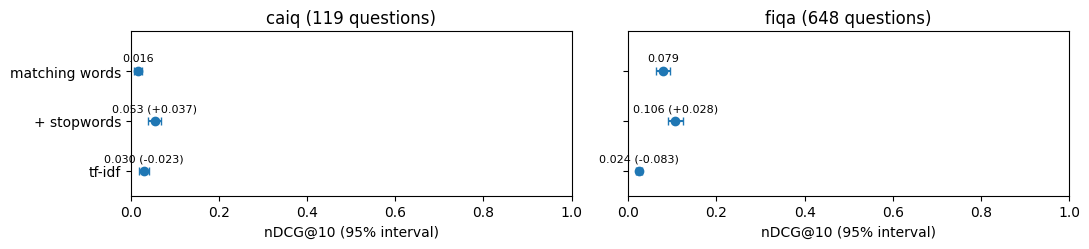

In [11]:
TFIDF = {ds.name: lab.tfidf(ds, ds.texts, STOP) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["tf-idf"] = lab.evaluate(ds, TFIDF[ds.name])
example = lab.example(caiq, runs["caiq"]["+ stopwords"], runs["caiq"]["tf-idf"], broken=True)
lab.show(caiq, example, {"+ stopwords": MATCH_STOP["caiq"], "tf-idf": TFIDF["caiq"]})
lab.plot_ladder(runs);

In [12]:
for d in lab.top(caiq, example, TFIDF["caiq"], 3):
    terms = STOP.terms(caiq.texts[caiq.row[d]])[0]
    common = sorted(set(terms), key=terms.count, reverse=True)[:5]
    print(f"{d}: {len(terms):,} terms; most frequent: " + ", ".join(f"{t} ×{terms.count(t)}" for t in common))

misc:008: 2,468 terms; most frequent: production ×571, separated ×285, non ×285, spa ×285, present ×285
misc:005: 2,985 terms; most frequent: trained ×251, octopus ×250, year ×250, programs ×250, provided ×250
misc:006: 2,981 terms; most frequent: security ×229, audit ×228, automated ×228, reviewed ×228, tools ×227


## 7. BM25

caiq: nDCG@10 0.030 before, 0.224 after; better 98, worse 0 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)

q:fimil:TVM-10.1: For Fimil: Are metrics for vulnerability identification and remediation established?

tf-idf  nDCG@10 0.000
  1. [.] misc:003       Untitled NA. Yes. Automated quarterly access reviews via Fimil-Ops endpoints. API token au…
  2. [.] misc:001       Untitled Yes. Yes. The organization maintains incident response procedures as part of Info…
  3. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…
  4. [.] misc:004       Untitled Yes. During annual ISO 27001 re- certification process or based on major changes …
  5. [.] misc:007       Untitled Yes. Yes. Audit logs stored in PostgreSQL with database-level access controls. Ad…

bm25  nDCG@10 0.542
  1. [1] present:TVM-10.1 Present SpA — TVM-10.1: Are metrics for vulnerability identification and remediation estab…
  2. [.] fimil:TVM-

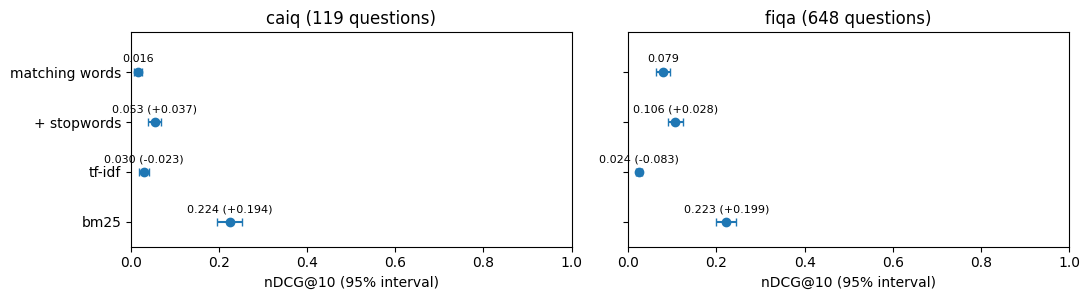

In [13]:
BM25 = {ds.name: lab.bm25(ds, ds.texts, analyzer=STOP) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["bm25"] = lab.evaluate(ds, BM25[ds.name])
example = lab.example(caiq, runs["caiq"]["tf-idf"], runs["caiq"]["bm25"])
lab.show(caiq, example, {"tf-idf": TFIDF["caiq"], "bm25": BM25["caiq"]})
lab.plot_ladder(runs);

caiq       b = 0  b = 0.25   b = 0.5  b = 0.75     b = 1
k1 0.6     0.049     0.188     0.216     0.233     0.243
k1 1.2     0.043     0.182     0.208     0.224     0.243
k1 2.0     0.042     0.165     0.195     0.217     0.238
fiqa       b = 0  b = 0.25   b = 0.5  b = 0.75     b = 1
k1 0.6     0.166     0.215     0.221     0.225     0.217
k1 1.2     0.165     0.214     0.221     0.223     0.201
k1 2.0     0.152     0.204     0.218     0.210     0.186


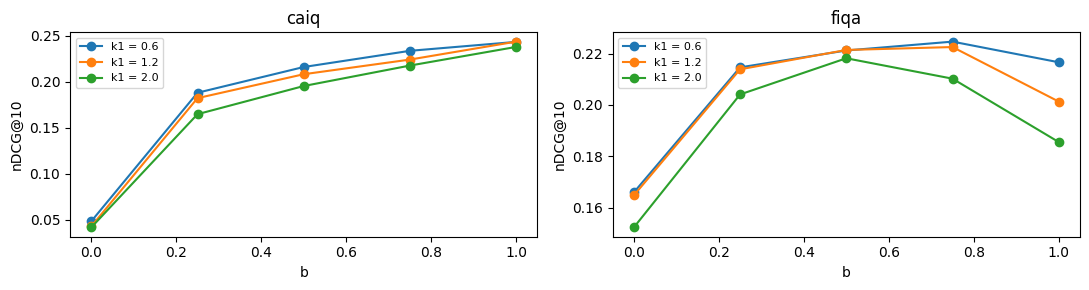

In [14]:
K1, B = (0.6, 1.2, 2.0), (0, 0.25, 0.5, 0.75, 1)
grid = {(ds.name, k1, b): np.mean(list(lab.evaluate(ds, lab.bm25(ds, ds.texts, k1, b, analyzer=STOP)).values()))
        for ds in DATASETS for k1 in K1 for b in B}
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    for k1 in K1:
        ax.plot(B, [grid[ds.name, k1, b] for b in B], marker="o", label=f"k1 = {k1}")
    ax.set_title(ds.name)
    ax.set_xlabel("b")
    ax.set_ylabel("nDCG@10")
    ax.legend(fontsize=8)
fig.tight_layout()
for ds in DATASETS:
    print(f"{ds.name:6s}" + "".join(f"{'b = ' + str(b):>10s}" for b in B))
    for k1 in K1:
        print(f"k1 {k1:<3}" + "".join(f"{grid[ds.name, k1, b]:10.3f}" for b in B))

## 8. Stemming

caiq: nDCG@10 0.224 before, 0.259 after; better 61, worse 41 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)

q:octopus:IVS-12.1: For Octopus Deploy: Are policies and procedures established and mechanisms configured and implemented to protect the wireless network environment perimeter and to restrict unauthorized wireless traffic?

bm25  nDCG@10 0.000
  1. [.] fimil:IVS-03.3 Fimil — IVS-03.3: Are communications between environments restricted to authenticated conn…
  2. [.] misc:005       Untitled Yes. Operator role is the highest privilege level (100). Impersonation limited to…
  3. [.] misc:009       Untitled NA. Cloud-hosted on DigitalOcean. Physical datacenter asset tracking is the cloud…
  4. [.] misc:006       Untitled Yes. Change Management Policy defines Emergency change type with expedited approv…
  5. [.] fimil:IVS-01.1 Fimil — IVS-01.1: Are infrastructure and virtualization security policies and procedures e…

+ stemming  nDCG@10 0.415
  1. [.] mis

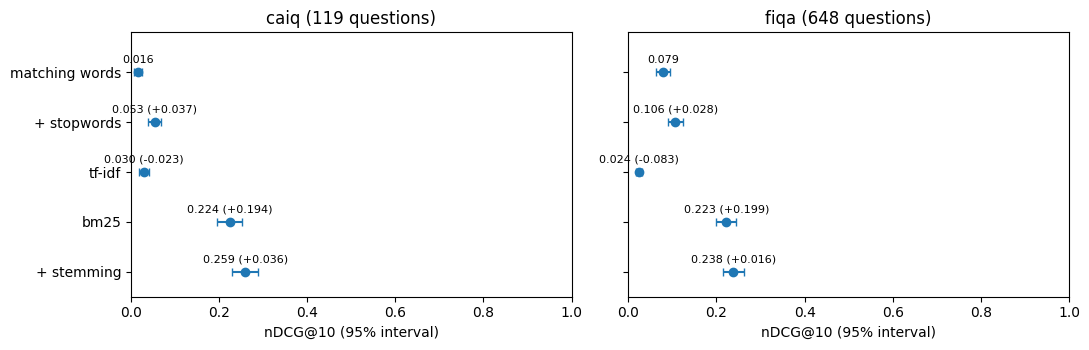

In [15]:
STEMMED = {ds.name: lab.bm25(ds, ds.texts, analyzer=STEM) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["+ stemming"] = lab.evaluate(ds, STEMMED[ds.name])
example = lab.example(caiq, runs["caiq"]["bm25"], runs["caiq"]["+ stemming"])
lab.show(caiq, example, {"bm25": BM25["caiq"], "+ stemming": STEMMED["caiq"]})
lab.plot_ladder(runs);

## 9. Add the title

caiq: text + title, IDF per field 0.513, IDF over title and text together 0.549


fiqa: text + title, IDF per field 0.238, IDF over title and text together 0.238
                      caiq               fiqa         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)
tf-idf               0.030 (-0.023)     0.024 (-0.083)
bm25                 0.224 (+0.194)     0.223 (+0.199)
+ stemming           0.259 (+0.036)     0.238 (+0.016)
+ title              0.549 (+0.290)     0.238 (+0.000)


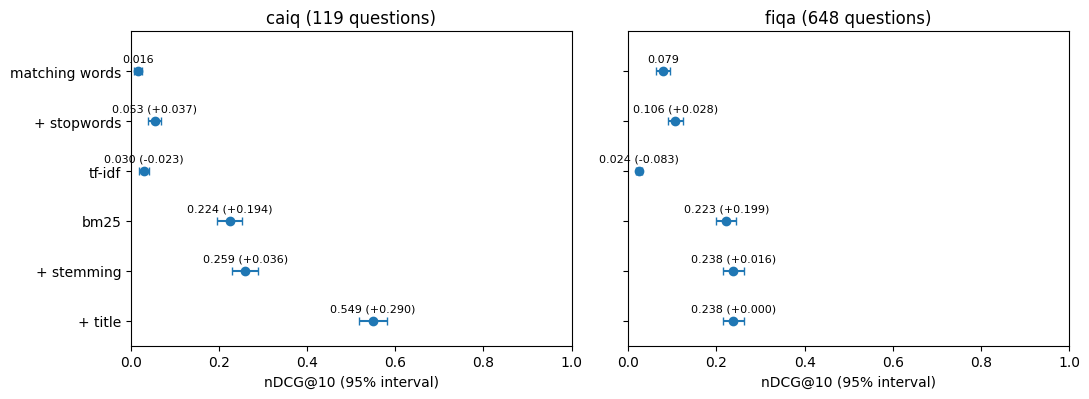

In [16]:
own = {ds.name: lab.bm25(ds, ds.titles, analyzer=STEM) for ds in DATASETS}  # the title's IDF from the titles alone
TEXT = {ds.name: lab.bm25(ds, ds.texts, idf_texts=ds.title_text, analyzer=STEM) for ds in DATASETS}  # from here on, every
TITLE = {ds.name: lab.bm25(ds, ds.titles, idf_texts=ds.title_text, analyzer=STEM) for ds in DATASETS}  # field's IDF is the same
for ds in DATASETS:
    per_field = lab.evaluate(ds, STEMMED[ds.name] + own[ds.name])
    shared = lab.evaluate(ds, TEXT[ds.name] + TITLE[ds.name])
    print(f"{ds.name}: text + title, IDF per field {np.mean(list(per_field.values())):.3f}, "
          f"IDF over title and text together {np.mean(list(shared.values())):.3f}")
    runs[ds.name]["+ title"] = shared
del own
lab.plot_ladder(runs);

In [17]:
example = lab.example(caiq, runs["caiq"]["+ stemming"], runs["caiq"]["+ title"])
lab.show(caiq, example, {"+ stemming": STEMMED["caiq"], "+ title": TEXT["caiq"] + TITLE["caiq"]})

caiq: nDCG@10 0.259 before, 0.549 after; better 117, worse 1 of 119 questions; fixed 6, broken 0 (from below 0.3 to above 0.7, or back)

q:realigned:BCR-11.1: For Realigned Technologies: Do you have technical capabilities to enforce tenant data retention policies?

+ stemming  nDCG@10 0.130
  1. [.] misc:009       Untitled NA. Cloud-hosted on DigitalOcean. Physical datacenter asset tracking is the cloud…
  2. [.] misc:010       Untitled NA. For the purpose of the questionnaire the question is not applicable, since wi…
  3. [.] misc:004       Untitled Yes. During annual ISO 27001 re- certification process or based on major changes …
  4. [1] fimil:DSP-16.1 Fimil — DSP-16.1: Do data retention, archiving, and deletion practices follow business req…
  5. [.] fimil:HRS-05.1 Fimil — HRS-05.1: Are return procedures of organizationally-owned assets by terminated emp…

+ title  nDCG@10 0.590
  1. [.] realigned:BCR-11.1 Realigned Technologies — BCR-11.1: Do you have technical capabilities to enf

## 10. Synonyms

In [18]:
ANALYZER = lab.Analyzer(stopwords=True, stemming=True, synonyms=lab.synonyms())  # every lexical step from here on
print(f"{len(ANALYZER.groups)} synonym groups, e.g.")
for group in ANALYZER.groups[:6]:
    print("  " + " | ".join(" ".join(p) for p in group))
for ds in DATASETS:
    found = sum(bool(ANALYZER.query(ds.queries[q])[1]) for q in ds.qids)
    print(f"{ds.name}: {found} of {len(ds.qids)} questions contain a synonym phrase")
words, groups = ANALYZER.query(caiq.queries[caiq.qids[0]])
print(f"\n{caiq.queries[caiq.qids[0]]}\n  words: {words}\n  phrases: {groups}")

53 synonym groups, e.g.
  non resident | nonresident
  exchange rate | fx rate | currency exchange rate
  octopus deploy | octopus | octopusdeploy
  dlp | data loss prevention | data leak prevention | data leakage prevention
  bcp | business continuity plan | business continuity planning | business continuity plans | bc plan
  encryption key | encryption keys | cryptographic key | cryptographic keys | crypto keys | crypto key
caiq: 79 of 119 questions contain a synonym phrase
fiqa: 249 of 648 questions contain a synonym phrase

For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained?
  words: ['fimil', 'risk', 'base', 'correct', 'action', 'plan', 'remedi', 'audit', 'find', 'document', 'communic', 'appli', 'evalu', 'maintain']
  phrases: [(['establish'], [[(0, 'set'), (1, 'up')], [(0, 'establish')]]), (['approv'], [[(0, 'approv')], [(0, 'author')], [(0, 'sanction')]])]


caiq: nDCG@10 0.549 before, 0.561 after; better 25, worse 12 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)

q:octopus:TVM-03.1: For Octopus Deploy: Is mobile code authorized before its installation and use, and the code configuration checked, to ensure that the authorized mobile code operates according to a clearly defined security policy?

+ title  nDCG@10 0.277
  1. [.] octopus:TVM-03.1 Octopus Deploy — TVM-03.1: Is mobile code authorized before its installation and use, and …
  2. [.] octopus:IAM-06.2 Octopus Deploy — IAM-06.2: Are controls in place to prevent unauthorized access to tenant …
  3. [.] octopus:BCR-10.1 Octopus Deploy — BCR-10.1: Are policies and procedures established and made available for …
  4. [1] octopus:MOS-03.1 Octopus Deploy — MOS-03.1: Do you have a policy enforcement capability (e.g., XACML) to en…
  5. [1] octopus:CCC-04.1 Octopus Deploy — CCC-04.1: Do you have controls in place to restrict and monitor the insta…

+ synonyms  nD

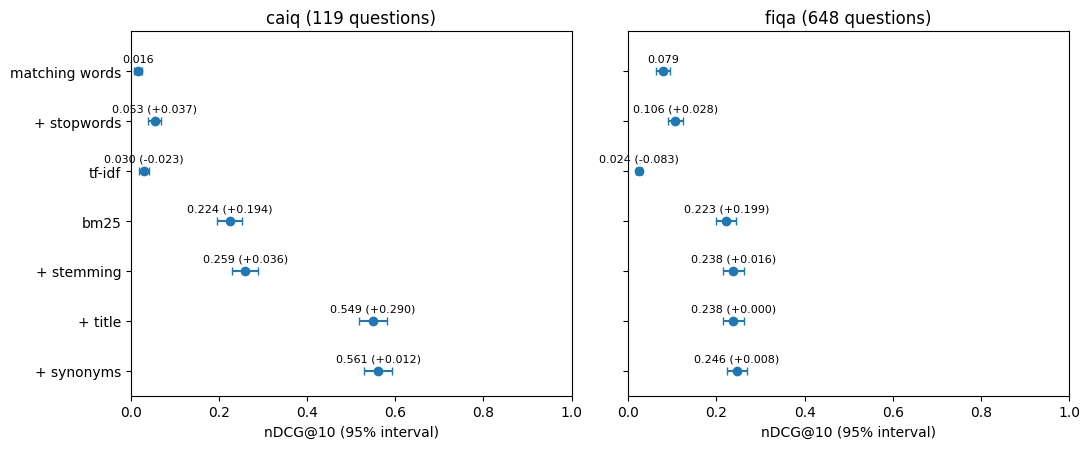

In [19]:
WITHOUT = {ds.name: TEXT[ds.name] + TITLE[ds.name] for ds in DATASETS}
TEXT = {ds.name: lab.bm25(ds, ds.texts, idf_texts=ds.title_text, analyzer=ANALYZER) for ds in DATASETS}
TITLE = {ds.name: lab.bm25(ds, ds.titles, idf_texts=ds.title_text, analyzer=ANALYZER) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["+ synonyms"] = lab.evaluate(ds, TEXT[ds.name] + TITLE[ds.name])
example = lab.example(caiq, runs["caiq"]["+ title"], runs["caiq"]["+ synonyms"])
lab.show(caiq, example, {"+ title": WITHOUT["caiq"], "+ synonyms": TEXT["caiq"] + TITLE["caiq"]})
lab.plot_ladder(runs);

## 11. Let's look at the top matches

In [20]:
def saturated(ds, S):
    return TEXT[ds.name] / (S + TEXT[ds.name]) + TITLE[ds.name] / (S + TITLE[ds.name])

example = lab.example(caiq, runs["caiq"]["+ synonyms"], lab.evaluate(caiq, saturated(caiq, 10)))
lab.show(caiq, example, {"+ synonyms": TEXT["caiq"] + TITLE["caiq"]})

caiq: nDCG@10 0.561 before, 0.542 after; better 39, worse 63 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)

q:octopus:IAM-06.2: For Octopus Deploy: Are controls in place to prevent unauthorized access to tenant application, program, or object source code, and assure it is restricted to authorized personnel only?

+ synonyms  nDCG@10 0.500
  1. [.] misc:010       Untitled NA. For the purpose of the questionnaire the question is not applicable, since wi…
  2. [.] octopus:IAM-06.2 Octopus Deploy — IAM-06.2: Are controls in place to prevent unauthorized access to tenant …
  3. [1] octopus:IAM-06.1 Octopus Deploy — IAM-06.1: Are controls in place to prevent unauthorized access to your ap…
  4. [1] realigned:IAM-06.1 Realigned Technologies — IAM-06.1: Are controls in place to prevent unauthorized access to…
  5. [1] octopus:IAM-02.1 Octopus Deploy — IAM-02.1: Do you have controls in place ensuring timely removal of system…



caiq: 11 irrelevant documents, 0.50 of them in the top 10 per question


fiqa: 114 irrelevant documents, 0.19 of them in the top 10 per question


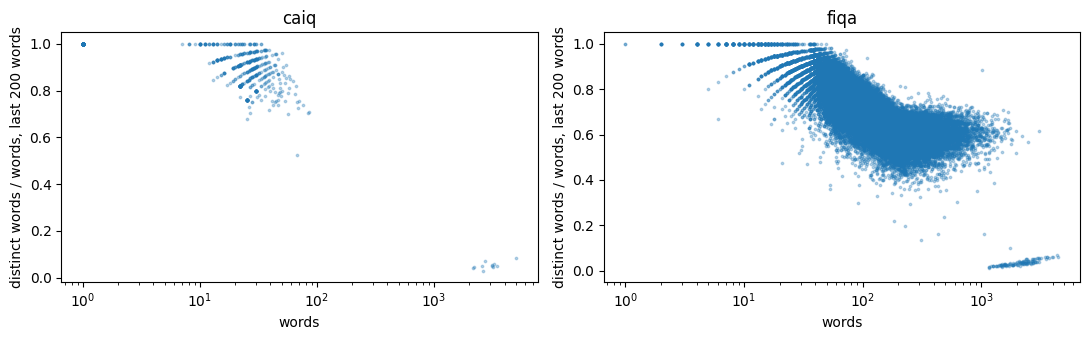

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
irrelevant = {}
for ax, ds in zip(axes, DATASETS):
    toks = [lab.tokenize(t) for t in ds.texts]
    n = np.array([len(t) for t in toks])
    distinct = np.array([len(set(t[-200:])) / max(len(t[-200:]), 1) for t in toks])
    ax.scatter(n, distinct, s=3, alpha=0.3)
    ax.set_xscale("log")
    ax.set_xlabel("words")
    ax.set_ylabel("distinct words / words, last 200 words")
    ax.set_title(ds.name)
    irrelevant[ds.name] = {d for d, k, r in zip(ds.ids, n, distinct) if k > 200 and r < 0.09}
fig.tight_layout()

for ds in DATASETS:
    rows = [ds.row[d] for d in irrelevant[ds.name]]
    in_top = np.isin(lab.topk(ds, TEXT[ds.name] + TITLE[ds.name]), rows).sum(1).mean()
    print(f"{ds.name}: {len(irrelevant[ds.name])} irrelevant documents, {in_top:.2f} of them in the top 10 per question")

## 12. Saturated BM25

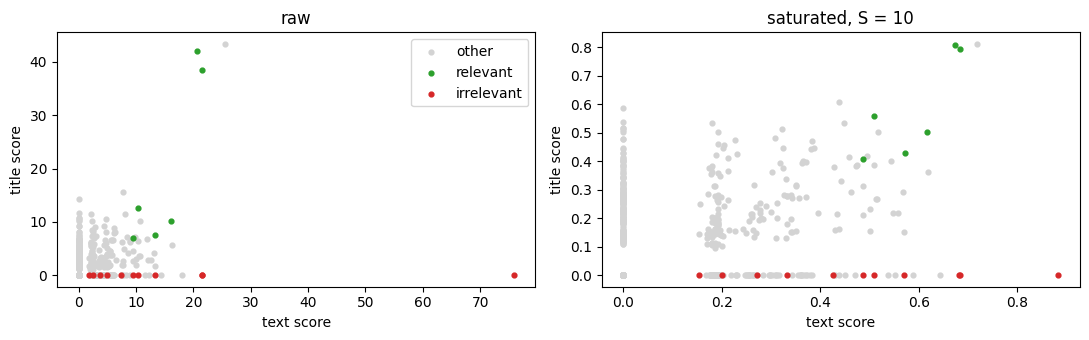

In [22]:
text, title = TEXT["caiq"][caiq.qrow[example]], TITLE["caiq"][caiq.qrow[example]]
is_irr = np.array([d in irrelevant["caiq"] for d in caiq.ids])
is_rel = np.array([caiq.qrels[example].get(d, 0) > 0 for d in caiq.ids])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, f) in zip(axes, (("raw", lambda x: x), ("saturated, S = 10", lambda x: x / (10 + x)))):
    for mask, label, color in ((~is_irr & ~is_rel, "other", "lightgrey"), (is_rel, "relevant", "C2"), (is_irr, "irrelevant", "C3")):
        ax.scatter(f(text[mask]), f(title[mask]), s=12, color=color, label=label)
    ax.set_xlabel("text score")
    ax.set_ylabel("title score")
    ax.set_title(name)
axes[0].legend()
fig.tight_layout()

{2: np.float64(0.523), 5: np.float64(0.534), 10: np.float64(0.542), 25: np.float64(0.567), 50: np.float64(0.567), 100: np.float64(0.563)}


                      caiq               fiqa         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)
tf-idf               0.030 (-0.023)     0.024 (-0.083)
bm25                 0.224 (+0.194)     0.223 (+0.199)
+ stemming           0.259 (+0.036)     0.238 (+0.016)
+ title              0.549 (+0.290)     0.238 (+0.000)
+ synonyms           0.561 (+0.012)     0.246 (+0.008)
saturated            0.567 (+0.006)     0.246 (+0.000)


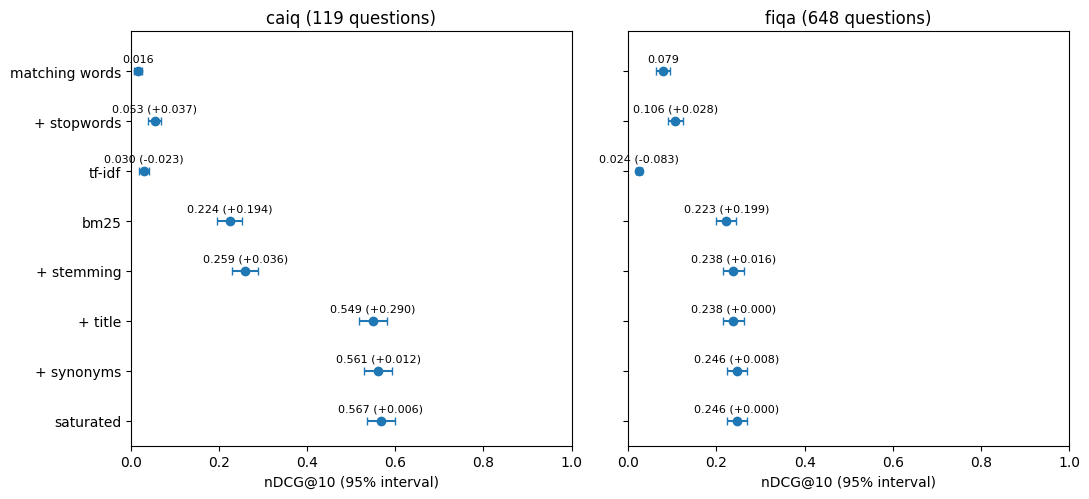

In [23]:
grid = {S: np.mean(list(lab.evaluate(caiq, saturated(caiq, S)).values())) for S in (2, 5, 10, 25, 50, 100)}
print({S: round(v, 3) for S, v in grid.items()})
S = max(grid, key=grid.get)
for ds in DATASETS:
    runs[ds.name]["saturated"] = lab.evaluate(ds, saturated(ds, S))
lab.plot_ladder(runs);

In [24]:
lab.show(caiq, example, {"+ synonyms": TEXT["caiq"] + TITLE["caiq"], "saturated": saturated(caiq, S)})

q:octopus:IAM-06.2: For Octopus Deploy: Are controls in place to prevent unauthorized access to tenant application, program, or object source code, and assure it is restricted to authorized personnel only?

+ synonyms  nDCG@10 0.500
  1. [.] misc:010       Untitled NA. For the purpose of the questionnaire the question is not applicable, since wi…
  2. [.] octopus:IAM-06.2 Octopus Deploy — IAM-06.2: Are controls in place to prevent unauthorized access to tenant …
  3. [1] octopus:IAM-06.1 Octopus Deploy — IAM-06.1: Are controls in place to prevent unauthorized access to your ap…
  4. [1] realigned:IAM-06.1 Realigned Technologies — IAM-06.1: Are controls in place to prevent unauthorized access to…
  5. [1] octopus:IAM-02.1 Octopus Deploy — IAM-02.1: Do you have controls in place ensuring timely removal of system…

saturated  nDCG@10 0.655
  1. [.] octopus:IAM-06.2 Octopus Deploy — IAM-06.2: Are controls in place to prevent unauthorized access to tenant …
  2. [1] octopus:IAM-06.1 Octopus

## 13. Phrase match

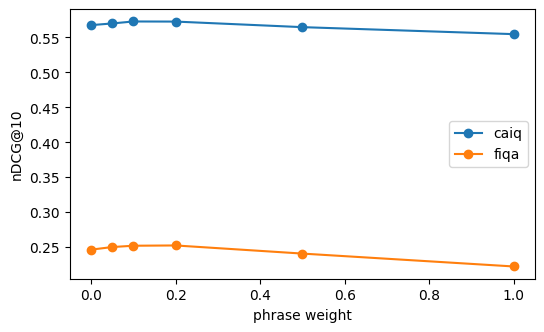

In [25]:
PHRASE_TEXT = {ds.name: lab.phrase(ds, ds.texts, ANALYZER) for ds in DATASETS}
PHRASE_TITLE = {ds.name: lab.phrase(ds, ds.titles, ANALYZER) for ds in DATASETS}
PHRASE = {n: 0.5 * PHRASE_TEXT[n] + PHRASE_TITLE[n] for n in PHRASE_TEXT}

def lexical(ds, w=0.2):
    return saturated(ds, S) + w * PHRASE[ds.name]

weights = (0, 0.05, 0.1, 0.2, 0.5, 1)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    ax.plot(weights, [np.mean(list(lab.evaluate(ds, lexical(ds, w)).values())) for w in weights], marker="o", label=ds.name)
ax.set_xlabel("phrase weight")
ax.set_ylabel("nDCG@10")
ax.legend()

                      caiq               fiqa         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)
tf-idf               0.030 (-0.023)     0.024 (-0.083)
bm25                 0.224 (+0.194)     0.223 (+0.199)
+ stemming           0.259 (+0.036)     0.238 (+0.016)
+ title              0.549 (+0.290)     0.238 (+0.000)
+ synonyms           0.561 (+0.012)     0.246 (+0.008)
saturated            0.567 (+0.006)     0.246 (+0.000)
+ phrase             0.572 (+0.005)     0.252 (+0.006)


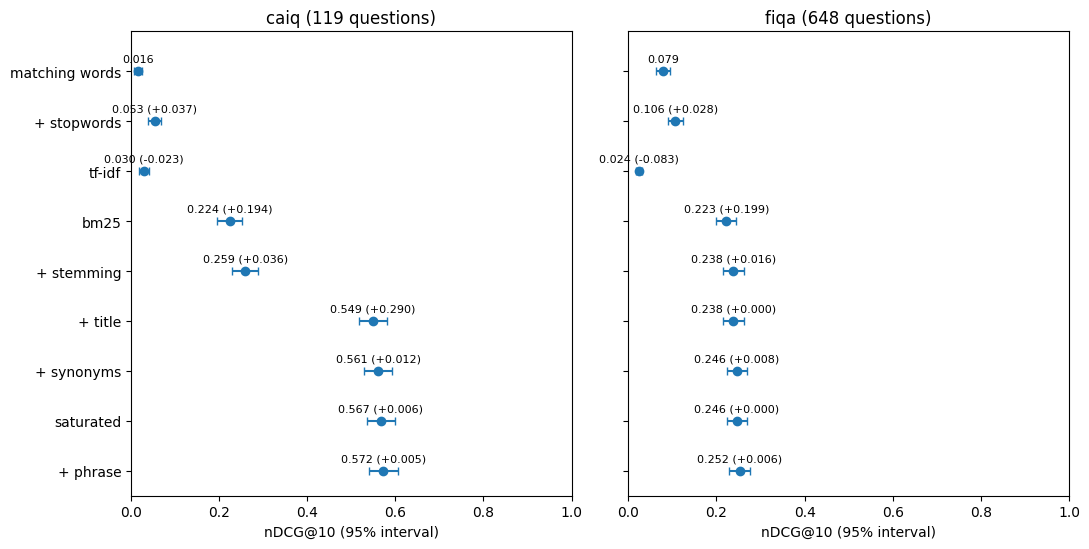

In [26]:
for ds in DATASETS:
    runs[ds.name]["+ phrase"] = lab.evaluate(ds, lexical(ds))
lab.plot_ladder(runs);

In [27]:
gain = {q: runs["fiqa"]["+ phrase"][q] - runs["fiqa"]["saturated"][q] for q in fiqa.qids}
example = max(gain, key=gain.get)
lab.show(fiqa, example, {"saturated": saturated(fiqa, S), "+ phrase": lexical(fiqa)})

7801: What are some well known or well regarded arguments against investing?



saturated  nDCG@10 0.387
  1. [.] 473434         On the contrary. Outsourcing to India and investing in India in general is quite profitabl…
  2. [1] 252574         "I think you're confusing risk analysis (that is what you quoted as ""Taleb Distribution""…
  3. [.] 71292          Some financial planners would not advise one way or the other on a specific stock without …
  4. [.] 355283         I can understand the argument that it's not a good allocation of resources to extend the l…
  5. [.] 246356         "&gt;Good luck arguing that in court while defending non-payment of taxes. Might want to l…



+ phrase  nDCG@10 0.818
  1. [1] 252574         "I think you're confusing risk analysis (that is what you quoted as ""Taleb Distribution""…
  2. [.] 473434         On the contrary. Outsourcing to India and investing in India in general is quite profitabl…
  3. [.] 355283         I can understand the argument that it's not a good allocation of resources to extend the l…
  4. [.] 246356         "&gt;Good luck arguing that in court while defending non-payment of taxes. Might want to l…
  5. [.] 71292          Some financial planners would not advise one way or the other on a specific stock without …



## 14. Learning to rank

In [28]:
import lightgbm as lgb

LEX_TOP = {ds.name: lab.topk(ds, lexical(ds), 50) for ds in DATASETS}
FEATURES = ("bm25 text", "bm25 title", "phrase text", "phrase title")

def parts(ds):
    """The lexical formula's parts, as the formula uses them."""
    n = ds.name
    return [TEXT[n] / (S + TEXT[n]), TITLE[n] / (S + TITLE[n]), PHRASE_TEXT[n], PHRASE_TITLE[n]]

RAW = {ds.name: np.stack([np.take_along_axis(p, LEX_TOP[ds.name], 1) for p in parts(ds)], -1) for ds in DATASETS}
SCALE = {n: (x.mean((0, 1)), np.maximum(x.std((0, 1)), 1e-9)) for n, x in RAW.items()}
X = {n: (x - SCALE[n][0]) / SCALE[n][1] for n, x in RAW.items()}
Y = {ds.name: lab.labels(ds, LEX_TOP[ds.name]) for ds in DATASETS}
GBM = dict(objective="lambdarank", learning_rate=0.05, num_leaves=7, deterministic=True, force_row_wise=True, verbose=-1)

def linear(x, y, ideal, x_test):
    return x_test @ lab.lambdarank(x, y, ideal)

def lightgbm(x, y, ideal, x_test):
    model = lgb.train(GBM, lgb.Dataset(x.reshape(-1, x.shape[-1]), y.reshape(-1), group=[x.shape[1]] * len(x)), 200)
    return model.predict(x_test.reshape(-1, x.shape[-1])).reshape(x_test.shape[:2])

LTR = {fit.__name__: {ds.name: lab.cross_validate(ds, X[ds.name], Y[ds.name], fit) for ds in DATASETS} for fit in (linear, lightgbm)}

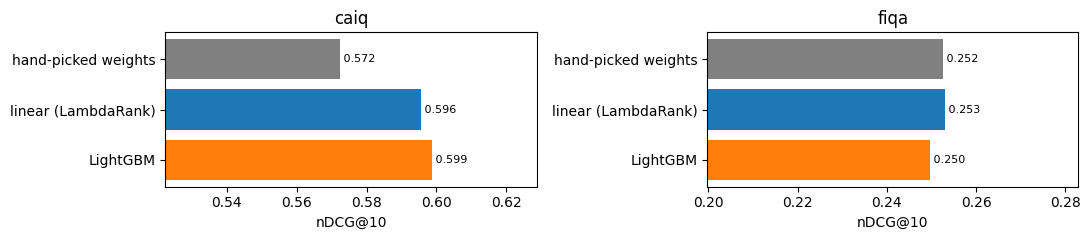

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.5))
for ax, ds in zip(axes, DATASETS):
    bars = {"hand-picked weights": np.take_along_axis(lexical(ds), LEX_TOP[ds.name], 1),
            "linear (LambdaRank)": LTR["linear"][ds.name], "LightGBM": LTR["lightgbm"][ds.name]}
    v = [np.mean(list(lab.evaluate_top(ds, LEX_TOP[ds.name], s).values())) for s in bars.values()]
    ax.barh(list(bars), v, color=["grey", "C0", "C1"])
    for k, x in enumerate(v):
        ax.text(x, k, f" {x:.3f}", va="center", fontsize=8)
    ax.set_xlim(min(v) - 0.05, max(v) + 0.03)
    ax.invert_yaxis()
    ax.set_title(ds.name)
    ax.set_xlabel("nDCG@10")
fig.tight_layout()

In [30]:
def fit_all(ds, x):
    """Mean nDCG@10 of the linear score trained on every question (in-sample: it only compares features)."""
    return np.mean(list(lab.evaluate_top(ds, LEX_TOP[ds.name], x @ lab.lambdarank(x, Y[ds.name], lab.ideal_dcg(ds))).values()))

for ds in DATASETS:
    w = lab.lambdarank(X[ds.name], Y[ds.name], lab.ideal_dcg(ds)) / SCALE[ds.name][1]  # weights on the formula's own parts
    w = w / w.max()
    print(f"{ds.name}: score = " + " + ".join(f"{v:.2f} · {f}" for f, v in zip(FEATURES, w) if v > 1e-3))

importance, full = {}, {}
for ds in DATASETS:
    booster = lgb.train(GBM, lgb.Dataset(X[ds.name].reshape(-1, len(FEATURES)), Y[ds.name].reshape(-1), group=[50] * len(ds.qids)), 200)
    gain = booster.feature_importance("gain") / max(booster.feature_importance("gain").sum(), 1e-9)
    full[ds.name] = fit_all(ds, X[ds.name])
    for i, f in enumerate(FEATURES):
        importance[ds.name, f] = (gain[i], fit_all(ds, np.delete(X[ds.name], i, -1)))
print(f"\n{'':16s}" + "".join(f"{ds.name + ' gain':>12s}{ds.name + ' nDCG without':>20s}" for ds in DATASETS))
print(f"{'(all features)':16s}" + "".join(f"{'':12s}{full[ds.name]:20.3f}" for ds in DATASETS))
for f in FEATURES:
    print(f"{f:16s}" + "".join(f"{importance[ds.name, f][0]:12.0%}{importance[ds.name, f][1]:20.3f}" for ds in DATASETS))

caiq: score = 0.54 · bm25 text + 1.00 · bm25 title + 0.05 · phrase title


fiqa: score = 1.00 · bm25 text + 0.06 · phrase text

                   caiq gain   caiq drop-one   fiqa gain   fiqa drop-one


bm25 text                23%          -0.049         84%          -0.049
bm25 title               72%          -0.082          0%          +0.000
phrase text               2%          +0.000         16%          -0.007
phrase title              3%          +0.000          0%          +0.000


                        caiq               fiqa         
matching words         0.016              0.079         
+ stopwords            0.053 (+0.037)     0.106 (+0.028)
tf-idf                 0.030 (-0.023)     0.024 (-0.083)
bm25                   0.224 (+0.194)     0.223 (+0.199)
+ stemming             0.259 (+0.036)     0.238 (+0.016)
+ title                0.549 (+0.290)     0.238 (+0.000)
+ synonyms             0.561 (+0.012)     0.246 (+0.008)
saturated              0.567 (+0.006)     0.246 (+0.000)
+ phrase               0.572 (+0.005)     0.252 (+0.006)
learning to rank       0.596 (+0.023)     0.253 (+0.000)


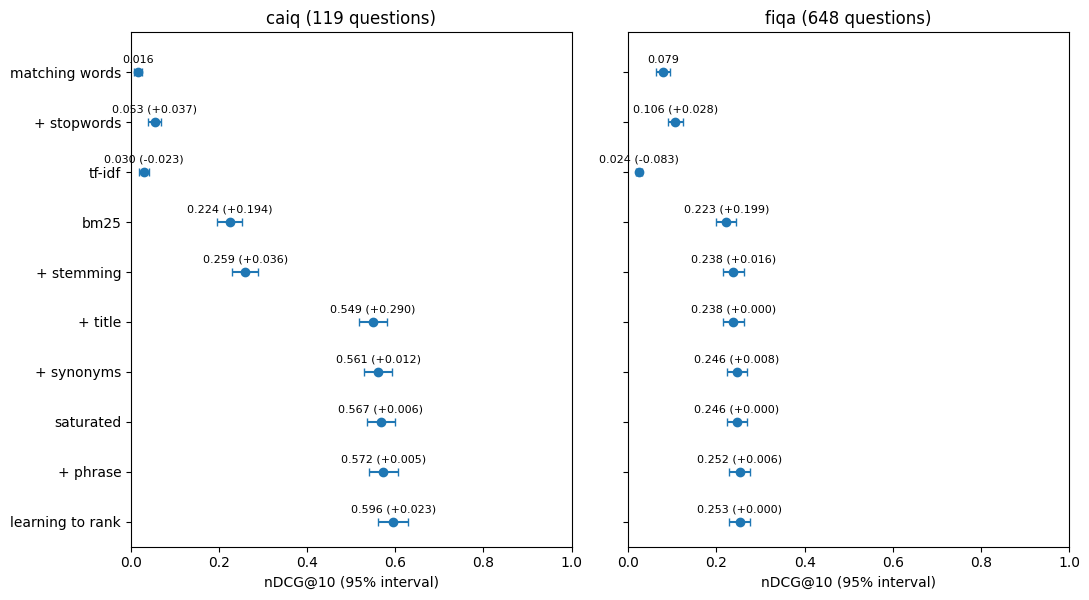

In [31]:
for ds in DATASETS:
    runs[ds.name]["learning to rank"] = lab.evaluate_top(ds, LEX_TOP[ds.name], LTR["linear"][ds.name])
lab.plot_ladder(runs);

In [32]:
gain = {q: runs["caiq"]["learning to rank"][q] - runs["caiq"]["+ phrase"][q] for q in caiq.qids}
example = max(gain, key=gain.get)
lab.show(caiq, example, {"+ phrase": lexical(caiq), "learning to rank": lab.expand(caiq, LEX_TOP["caiq"], LTR["linear"]["caiq"])})

q:fimil:LOG-06.1: For Fimil: Is a reliable time source being used across all relevant systems?

+ phrase  nDCG@10 0.307
  1. [.] fimil:LOG-06.1 Fimil — LOG-06.1: Is a reliable time source being used across all relevant systems? Yes. A…
  2. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…
  3. [1] present:LOG-06.1 Present SpA — LOG-06.1: Is a reliable time source being used across all relevant informati…
  4. [.] octopus:TVM-01.1 Octopus Deploy — TVM-01.1: Do you have anti-malware programs that support or connect to yo…
  5. [.] octopus:IVS-12.3 Octopus Deploy — IVS-12.3: Are policies and procedures established and mechanisms implemen…

learning to rank  nDCG@10 0.818
  1. [1] present:LOG-06.1 Present SpA — LOG-06.1: Is a reliable time source being used across all relevant informati…
  2. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…
  3. [.] octopus:TVM-02.5 O

## 15. Dense embeddings

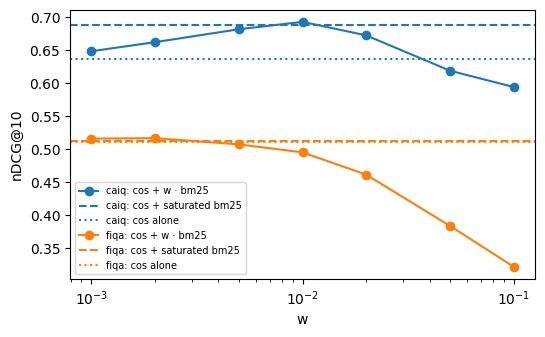

In [33]:
VEC = {ds.name: lab.vectors(ds) for ds in DATASETS}
COS = {name: q @ d.T for name, (d, q) in VEC.items()}
dense = {ds.name: lab.evaluate(ds, COS[ds.name]) for ds in DATASETS}

def naive(ds, w):
    return COS[ds.name] + w * (TEXT[ds.name] + TITLE[ds.name])

def hybrid(ds):
    return 4 * np.maximum(0, COS[ds.name] - 0.05) + lexical(ds)

weights = (0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    curve = [np.mean(list(lab.evaluate(ds, naive(ds, w)).values())) for w in weights]
    ax.plot(weights, curve, marker="o", label=f"{ds.name}: cos + w · bm25")
    color = ax.lines[-1].get_color()
    ax.axhline(np.mean(list(lab.evaluate(ds, hybrid(ds)).values())), ls="--", color=color, label=f"{ds.name}: cos + saturated bm25")
    ax.axhline(np.mean(list(dense[ds.name].values())), ls=":", color=color, label=f"{ds.name}: cos alone")
ax.set_xscale("log")
ax.set_xlabel("w")
ax.set_ylabel("nDCG@10")
ax.legend(fontsize=7)

In [34]:
def rrf(k, *scores, depth=1000):
    """Reciprocal rank fusion of each list's top `depth`: a document gains 1 / (k + rank) from every list that has it."""
    out = np.zeros(scores[0].shape, dtype=np.float32)
    depth = min(depth, out.shape[1])
    for s in scores:
        top = np.argpartition(-s, depth - 1, axis=1)[:, :depth]  # the top `depth`, unordered: no full sort needed
        top = np.take_along_axis(top, np.argsort(-np.take_along_axis(s, top, 1), axis=1), 1)
        gain = np.zeros_like(out)
        np.put_along_axis(gain, top, 1 / (k + np.arange(1, depth + 1, dtype=np.float32)), 1)
        out += gain
    return out

RRF_K = {"caiq": 10, "fiqa": 1}  # the best k of 1, 10, 30, 60, 100, 300 and 1000 on these questions
for ds in DATASETS:
    mean = lambda s: np.mean(list(lab.evaluate(ds, s).values()))
    print(f"{ds.name}: cos + saturated bm25 {mean(hybrid(ds)):.3f}, "
          f"RRF of the two (best k = {RRF_K[ds.name]}) {mean(rrf(RRF_K[ds.name], COS[ds.name], lexical(ds))):.3f}, "
          f"cos alone {np.mean(list(dense[ds.name].values())):.3f}, saturated bm25 alone {mean(lexical(ds)):.3f}")

caiq: cos + saturated bm25 0.688, RRF of the two (best k = 10) 0.674, cos alone 0.636, saturated bm25 alone 0.572


fiqa: cos + saturated bm25 0.512, RRF of the two (best k = 1) 0.457, cos alone 0.511, saturated bm25 alone 0.252


                        caiq               fiqa         
matching words         0.016              0.079         
+ stopwords            0.053 (+0.037)     0.106 (+0.028)
tf-idf                 0.030 (-0.023)     0.024 (-0.083)
bm25                   0.224 (+0.194)     0.223 (+0.199)
+ stemming             0.259 (+0.036)     0.238 (+0.016)
+ title                0.549 (+0.290)     0.238 (+0.000)
+ synonyms             0.561 (+0.012)     0.246 (+0.008)
saturated              0.567 (+0.006)     0.246 (+0.000)
+ phrase               0.572 (+0.005)     0.252 (+0.006)
learning to rank       0.596 (+0.023)     0.253 (+0.000)
+ dense                0.688 (+0.092)     0.512 (+0.259)


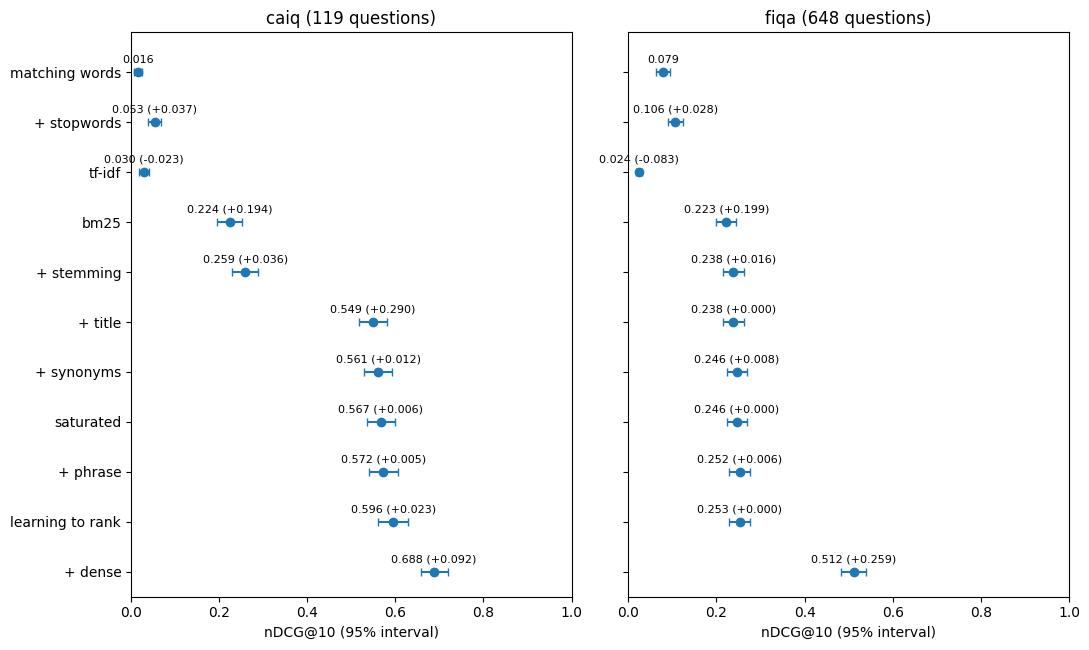

In [35]:
for ds in DATASETS:
    runs[ds.name]["+ dense"] = lab.evaluate(ds, hybrid(ds))
lab.plot_ladder(runs);

In [36]:
gain = {q: runs["fiqa"]["+ dense"][q] - runs["fiqa"]["+ phrase"][q] for q in fiqa.qids}
example = max(gain, key=gain.get)
lab.show(fiqa, example, {"+ phrase": lexical(fiqa), "+ dense": hybrid(fiqa)})

15: Can I send a money order from USPS as a business?



+ phrase  nDCG@10 0.000
  1. [.] 420483         On your end of the deal, the biggest risk is probably counterfeiting. That said, I'd think…
  2. [.] 230003         "&gt; ""So I'll either stop shipping prescriptions or switch to FedEx or UPS -- which cost…
  3. [.] 321826         Not sure why USPS wouldn't put the screws to stamps.com. Stamps might be sending a lot of …
  4. [.] 224000         "A money order is basically a pre-paid check. The physical cash would probably get deposit…
  5. [.] 454734         The net benefit to the US economy for the DoD is likely positive thanks to the Navy alone,…



+ dense  nDCG@10 1.000
  1. [1] 325273         Sure you can. You can fill in whatever you want in the From section of a money order, so y…
  2. [.] 224000         "A money order is basically a pre-paid check. The physical cash would probably get deposit…
  3. [.] 420483         On your end of the deal, the biggest risk is probably counterfeiting. That said, I'd think…
  4. [.] 233145         I assume you kept the receipt for your money order, in which case there's no reason you ca…
  5. [.] 284528         The US Postal Service to my recollection recommends only mailing cash or items with cash-l…



## 16. Long documents

In [37]:
VEC512 = {ds.name: lab.vectors(ds, window=512) for ds in DATASETS}
COS512 = {name: q @ d.T for name, (d, q) in VEC512.items()}
for ds in DATASETS:
    long = (VEC512[ds.name][0] != VEC[ds.name][0]).any(1)
    rel = [ds.row[d] for q in ds.qids for d, g in ds.qrels[q].items() if g > 0 and d in ds.row]
    irr = np.array([d in irrelevant[ds.name] for d in ds.ids])
    print(f"{ds.name}: {long.sum():,} documents longer than 512 tokens ({long.mean():.1%}); "
          f"{long[rel].mean():.1%} of relevant documents, {long[irr].mean():.0%} of irrelevant ones")

caiq: 11 documents longer than 512 tokens (1.7%); 0.0% of relevant documents, 100% of irrelevant ones
fiqa: 2,435 documents longer than 512 tokens (4.2%); 7.8% of relevant documents, 100% of irrelevant ones


caiq, window 512 tokens: an irrelevant document in the dense top 10 for 19% of questions
caiq, window whole document: an irrelevant document in the dense top 10 for 15% of questions


fiqa, window 512 tokens: an irrelevant document in the dense top 10 for 1% of questions


fiqa, window whole document: an irrelevant document in the dense top 10 for 8% of questions


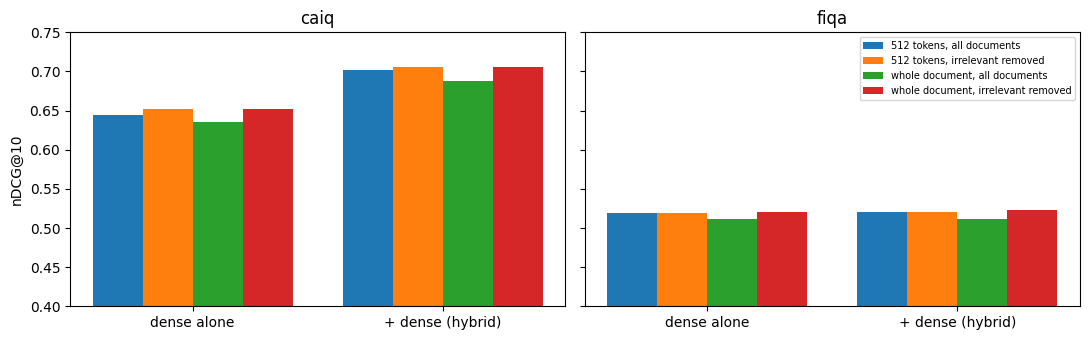

In [38]:
def with_cos(ds, cos):
    return 4 * np.maximum(0, cos - 0.05) + lexical(ds)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, ds in zip(axes, DATASETS):
    keep = np.array([d not in irrelevant[ds.name] for d in ds.ids])
    bars = {}
    for window, cos in (("512 tokens", COS512[ds.name]), ("whole document", COS[ds.name])):
        for docs, mask in (("all documents", np.ones_like(keep)), ("irrelevant removed", keep)):
            bars[f"{window}, {docs}"] = [np.mean(list(lab.evaluate(ds, np.where(mask, s, -np.inf)).values()))
                                         for s in (cos, with_cos(ds, cos))]
        top = lab.topk(ds, cos, 10)
        print(f"{ds.name}, window {window}: an irrelevant document in the dense top 10 for "
              f"{(~keep)[top].any(1).mean():.0%} of questions")
    for k, (label, v) in enumerate(bars.items()):
        ax.bar(np.arange(2) + k * 0.2 - 0.3, v, 0.2, label=label)
    ax.set_xticks(range(2), ["dense alone", "+ dense (hybrid)"])
    ax.set_ylim(0.4, 0.75)
    ax.set_title(ds.name)
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=7)
fig.tight_layout()

In [39]:
keep = np.array([d not in irrelevant["fiqa"] for d in fiqa.ids])
top512, top = lab.topk(fiqa, COS512["fiqa"], 10), lab.topk(fiqa, COS["fiqa"], 10)
climbed = [q for r, q in enumerate(fiqa.qids) if (~keep)[top[r]].any() and not (~keep)[top512[r]].any()]
lab.show(fiqa, climbed[0], {"512 tokens": COS512["fiqa"], "whole document": COS["fiqa"]})

549: Where to request ACH Direct DEBIT of funds from MY OWN personal bank account?



512 tokens  nDCG@10 1.000
  1. [1] 214024         Call Wells Fargo or go to a branch. Tell them what you're trying to accomplish, not the ve…
  2. [.] 221061         "Generally, ACH transfers are not considered direct deposits. However, you can pay for thi…
  3. [.] 595633         Typically, a direct debit is set up by the company who will be receiving the money, not by…
  4. [.] 240328         The RDFI (Receiving Depository Institution) is the place where you keep your money and whe…
  5. [.] 190537         I had a similar situation a while ago, and here's what I learned: What are our options her…



whole document  nDCG@10 0.631
  1. [.] 600049         A special 24/7 available QuickBooks support phone number helpline for users who are gettin…
  2. [1] 214024         Call Wells Fargo or go to a branch. Tell them what you're trying to accomplish, not the ve…
  3. [.] 221061         "Generally, ACH transfers are not considered direct deposits. However, you can pay for thi…
  4. [.] 595633         Typically, a direct debit is set up by the company who will be receiving the money, not by…
  5. [.] 240328         The RDFI (Receiving Depository Institution) is the place where you keep your money and whe…



## 17. Binary embeddings

In [40]:
def signs(x):
    return np.where(x >= 0, 1, -1).astype(np.float32)

BIN, CENTERED, ASYM = {}, {}, {}
for ds in DATASETS:
    d, q = VEC[ds.name]
    mean = d.mean(0)
    BIN[ds.name] = signs(q) @ signs(d).T
    CENTERED[ds.name] = signs(q - mean) @ signs(d - mean).T
    ASYM[ds.name] = (q - mean) @ signs(d - mean).T / np.sqrt(d.shape[1])  # the question stays float; documents are bits
    print(f"{ds.name}: {d.nbytes / 1e6:.1f} MB as float32, {np.packbits(d >= 0, axis=1).nbytes / 1e6:.2f} MB as bits; "
          f"nDCG@10 float {np.mean(list(dense[ds.name].values())):.3f}, "
          f"bits {np.mean(list(lab.evaluate(ds, BIN[ds.name]).values())):.3f}, "
          f"centered bits {np.mean(list(lab.evaluate(ds, CENTERED[ds.name]).values())):.3f}, "
          f"float question × centered bits {np.mean(list(lab.evaluate(ds, ASYM[ds.name]).values())):.3f}")

caiq: 2.6 MB as float32, 0.08 MB as bits; nDCG@10 float 0.636, bits 0.598, centered bits 0.608, float question × centered bits 0.618


fiqa: 237.2 MB as float32, 7.41 MB as bits; nDCG@10 float 0.511, bits 0.483, centered bits 0.485, float question × centered bits 0.503


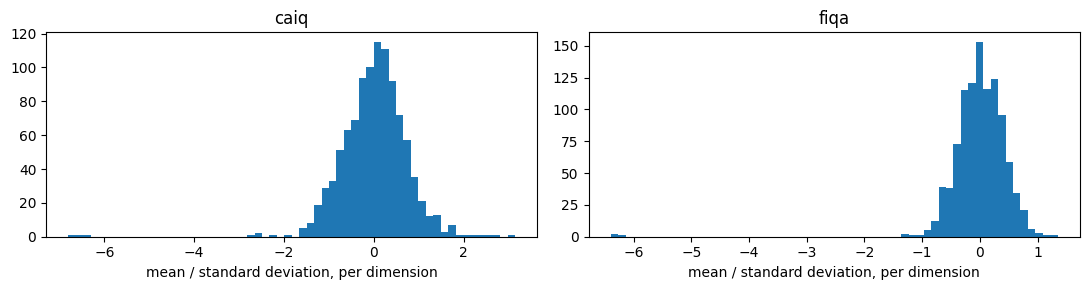

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    d, _ = VEC[ds.name]
    ax.hist(d.mean(0) / d.std(0), bins=60)
    ax.set_title(ds.name)
    ax.set_xlabel("mean / standard deviation, per dimension")
fig.tight_layout()

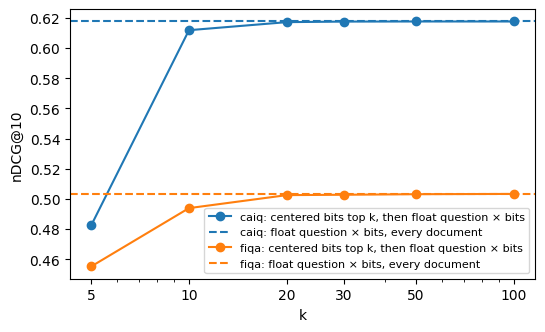

In [42]:
windows = (5, 10, 20, 30, 50, 100)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    top = lab.topk(ds, CENTERED[ds.name], max(windows))  # the bits' top 100, once; each window is a prefix of it
    asym = np.take_along_axis(ASYM[ds.name], top, 1)
    curve = [np.mean(list(lab.evaluate_top(ds, top[:, :k], asym[:, :k]).values())) for k in windows]
    ax.plot(windows, curve, marker="o", label=f"{ds.name}: centered bits top k, then float question × bits")
    ax.axhline(np.mean(list(lab.evaluate(ds, ASYM[ds.name]).values())), ls="--", color=ax.lines[-1].get_color(),
               label=f"{ds.name}: float question × bits, every document")
ax.set_xscale("log")
ax.set_xticks(windows, windows)
ax.set_xlabel("k")
ax.set_ylabel("nDCG@10")
ax.legend(fontsize=8)

                          caiq               fiqa         
matching words           0.016              0.079         
+ stopwords              0.053 (+0.037)     0.106 (+0.028)
tf-idf                   0.030 (-0.023)     0.024 (-0.083)
bm25                     0.224 (+0.194)     0.223 (+0.199)
+ stemming               0.259 (+0.036)     0.238 (+0.016)
+ title                  0.549 (+0.290)     0.238 (+0.000)
+ synonyms               0.561 (+0.012)     0.246 (+0.008)
saturated                0.567 (+0.006)     0.246 (+0.000)
+ phrase                 0.572 (+0.005)     0.252 (+0.006)
learning to rank         0.596 (+0.023)     0.253 (+0.000)
+ dense                  0.688 (+0.092)     0.512 (+0.259)
binary first stage       0.684 (-0.004)     0.505 (-0.007)


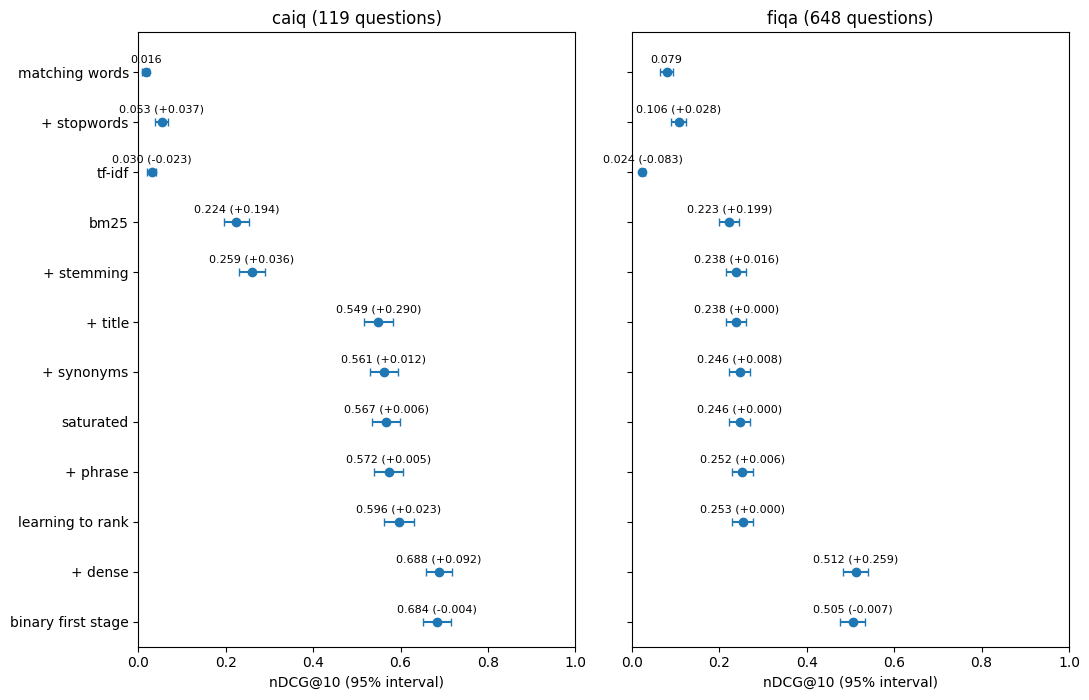

In [43]:
def hybrid_bits(ds):
    return 4 * np.maximum(0, ASYM[ds.name]) + lexical(ds)

CAND = {ds.name: lab.candidates(ds, [CENTERED[ds.name], TEXT[ds.name] + TITLE[ds.name]], 20) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["binary first stage"] = lab.evaluate(ds, np.where(CAND[ds.name], hybrid_bits(ds), -np.inf))
lab.plot_ladder(runs);

## 18. Late interaction

Late interaction (ColBERT) keeps one vector per token and matches each question token to its best document token. Its value depends on the model and dataset: LateOn improves FiQA, but contributes almost nothing on CAIQ. This section compares three precomputed models with Perplexity's new v2 0.6B model.

In [44]:
STEP5 = {ds.name: np.where(CAND[ds.name], hybrid_bits(ds), -np.inf) for ds in DATASETS}
TOP20 = {ds.name: lab.topk(ds, STEP5[ds.name], 20) for ds in DATASETS}

def at(ds, scores):
    return np.take_along_axis(scores, TOP20[ds.name], 1)

def minmax(x):
    lo, hi = x.min(1, keepdims=True), x.max(1, keepdims=True)
    return (x - lo) / np.maximum(hi - lo, 1e-9)

TOK = {ds.name: lab.late_tokens(ds, ENCODE_ON_GPU) for ds in DATASETS}
d_bytes = 1024 * 2
for ds in DATASETS:
    n = np.diff(TOK[ds.name].start).mean()
    print(f"{ds.name}: dense, one vector per document: {d_bytes:,} bytes as float16, {d_bytes // 16:,} as bits; pplx v2-late, "
          f"{n:.0f} vectors of 128 per document: {n * 256:,.0f} bytes as float16, {n * 128:,.0f} as int8, {n * 16:,.0f} as bits")

caiq: dense, one vector per document: 2,048 bytes as float16, 128 as bits; pplx v2-late, 107 vectors of 128 per document: 27,379 bytes as float16, 13,689 as int8, 1,711 as bits
fiqa: dense, one vector per document: 2,048 bytes as float16, 128 as bits; pplx v2-late, 163 vectors of 128 per document: 41,622 bytes as float16, 20,811 as int8, 2,601 as bits


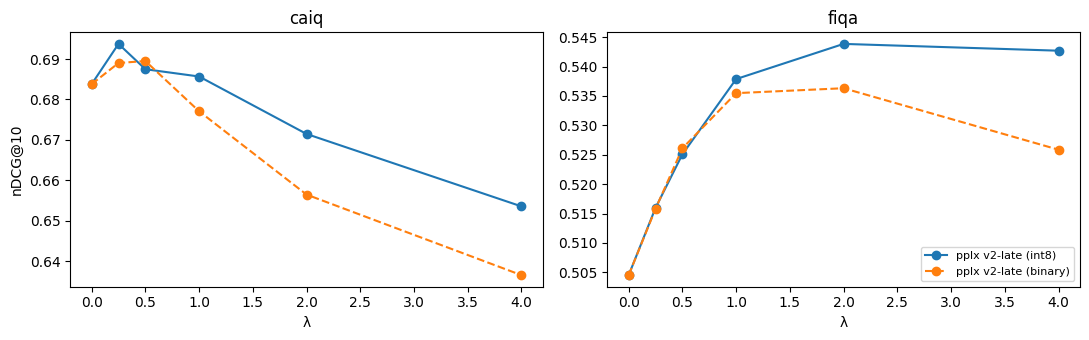

In [45]:
LATE = {form: {ds.name: lab.maxsim(ds, TOK[ds.name], TOP20[ds.name], binary=form == "binary") for ds in DATASETS}
        for form in ("int8", "binary")}

def fused(ds, scores, lam):
    return minmax(at(ds, STEP5[ds.name])) + lam * minmax(scores)

lams = (0, 0.25, 0.5, 1, 2, 4)
CURVE = {(form, ds.name): [np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], fused(ds, LATE[form][ds.name], lam)).values()))
                           for lam in lams] for form in LATE for ds in DATASETS}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, ds in zip(axes, DATASETS):
    for form, ls in (("int8", "-"), ("binary", "--")):
        ax.plot(lams, CURVE[form, ds.name], ls=ls, marker="o", label=f"pplx v2-late ({form})")
    ax.set_title(ds.name)
    ax.set_xlabel("λ")
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=8)
fig.tight_layout()

In [46]:
for ds in DATASETS:
    alone = {"step 5": at(ds, STEP5[ds.name]), **{f"pplx v2-late ({form})": LATE[form][ds.name] for form in LATE}}
    print(f"{ds.name}, the same top 20 ordered by " + ", ".join(
        f"{name} {np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], s).values())):.3f}" for name, s in alone.items()))

caiq, the same top 20 ordered by step 5 0.684, pplx v2-late (int8) 0.630, pplx v2-late (binary) 0.618
fiqa, the same top 20 ordered by step 5 0.505, pplx v2-late (int8) 0.532, pplx v2-late (binary) 0.500


{'caiq': 0.5, 'fiqa': 2}
                          caiq               fiqa         
matching words           0.016              0.079         
+ stopwords              0.053 (+0.037)     0.106 (+0.028)
tf-idf                   0.030 (-0.023)     0.024 (-0.083)
bm25                     0.224 (+0.194)     0.223 (+0.199)
+ stemming               0.259 (+0.036)     0.238 (+0.016)
+ title                  0.549 (+0.290)     0.238 (+0.000)
+ synonyms               0.561 (+0.012)     0.246 (+0.008)
saturated                0.567 (+0.006)     0.246 (+0.000)
+ phrase                 0.572 (+0.005)     0.252 (+0.006)
learning to rank         0.596 (+0.023)     0.253 (+0.000)
+ dense                  0.688 (+0.092)     0.512 (+0.259)
binary first stage       0.684 (-0.004)     0.505 (-0.007)
+ late interaction       0.690 (+0.006)     0.536 (+0.032)


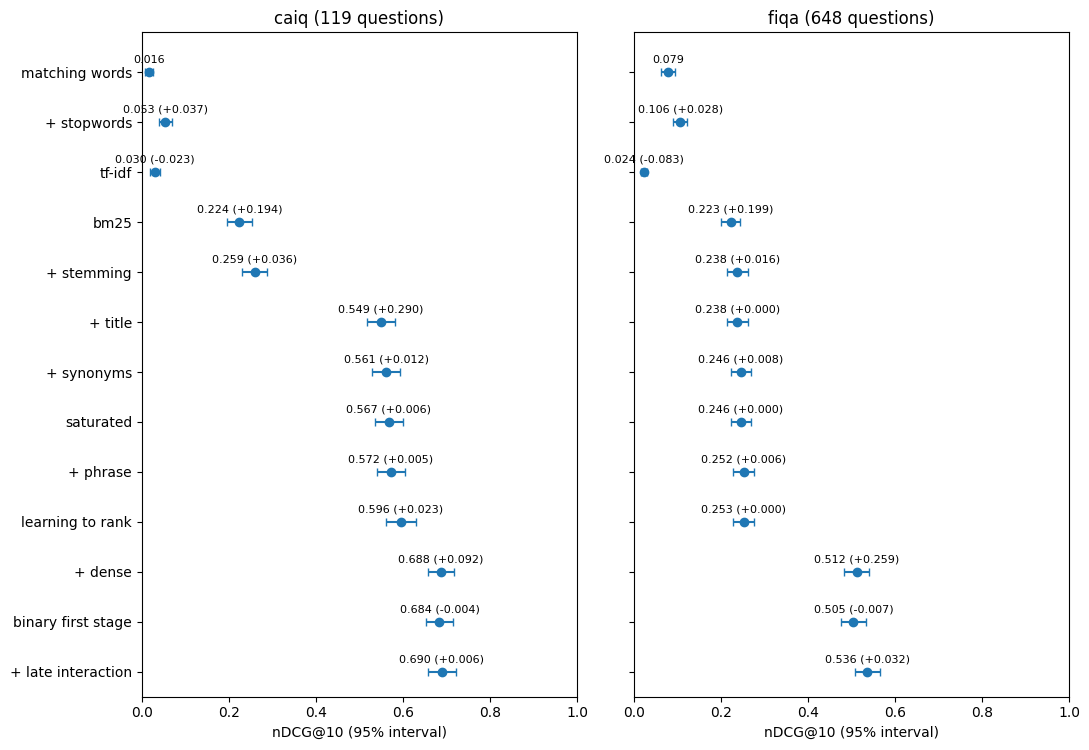

In [47]:
LAM_LATE = {ds.name: lams[int(np.argmax(CURVE["binary", ds.name]))] for ds in DATASETS}  # read off the curves above
print(LAM_LATE)
for ds in DATASETS:
    runs[ds.name]["+ late interaction"] = lab.evaluate_top(ds, TOP20[ds.name], fused(ds, LATE["binary"][ds.name], LAM_LATE[ds.name]))
lab.plot_ladder(runs);

In [48]:
for ds in DATASETS:
    n = np.diff(TOK[ds.name].start).mean()
    size = {"int8": n * 128, "binary": n * 16}
    print(f"{ds.name}: " + ", ".join(f"{form} {max(CURVE[form, ds.name]):.3f} ({size[form]:,.0f} bytes per document)" for form in LATE))

caiq: int8 0.694 (13,689 bytes per document), binary 0.690 (1,711 bytes per document)
fiqa: int8 0.544 (20,811 bytes per document), binary 0.536 (2,601 bytes per document)


## 19. Cross-encoder

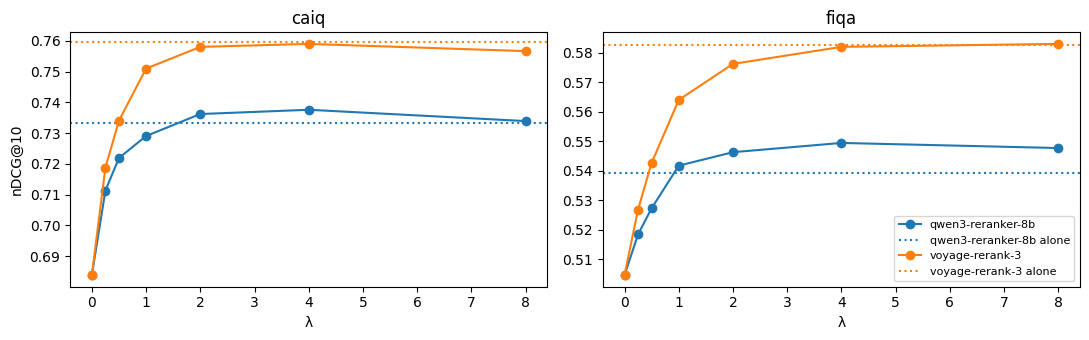

In [49]:
MODELS = ("qwen3-reranker-8b", "voyage-rerank-3")
CE = {m: {ds.name: lab.rerank(ds, TOP20[ds.name], m) for ds in DATASETS} for m in MODELS}

def reranked(ds, lam, model):
    return minmax(at(ds, STEP5[ds.name])) + lam * minmax(CE[model][ds.name])

lams = (0, 0.25, 0.5, 1, 2, 4, 8)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, ds in zip(axes, DATASETS):
    for m in MODELS:
        ax.plot(lams, [np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], reranked(ds, lam, m)).values())) for lam in lams],
                marker="o", label=m)
        ax.axhline(np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], CE[m][ds.name]).values())), ls=":",
                   color=ax.lines[-1].get_color(), label=f"{m} alone")
    ax.set_title(ds.name)
    ax.set_xlabel("λ")
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=8)
fig.tight_layout()

{'caiq': 4, 'fiqa': 8}
                          caiq               fiqa         
matching words           0.016              0.079         
+ stopwords              0.053 (+0.037)     0.106 (+0.028)
tf-idf                   0.030 (-0.023)     0.024 (-0.083)
bm25                     0.224 (+0.194)     0.223 (+0.199)
+ stemming               0.259 (+0.036)     0.238 (+0.016)
+ title                  0.549 (+0.290)     0.238 (+0.000)
+ synonyms               0.561 (+0.012)     0.246 (+0.008)
saturated                0.567 (+0.006)     0.246 (+0.000)
+ phrase                 0.572 (+0.005)     0.252 (+0.006)
learning to rank         0.596 (+0.023)     0.253 (+0.000)
+ dense                  0.688 (+0.092)     0.512 (+0.259)
binary first stage       0.684 (-0.004)     0.505 (-0.007)
+ late interaction       0.690 (+0.006)     0.536 (+0.032)
+ cross-encoder          0.759 (+0.069)     0.583 (+0.047)


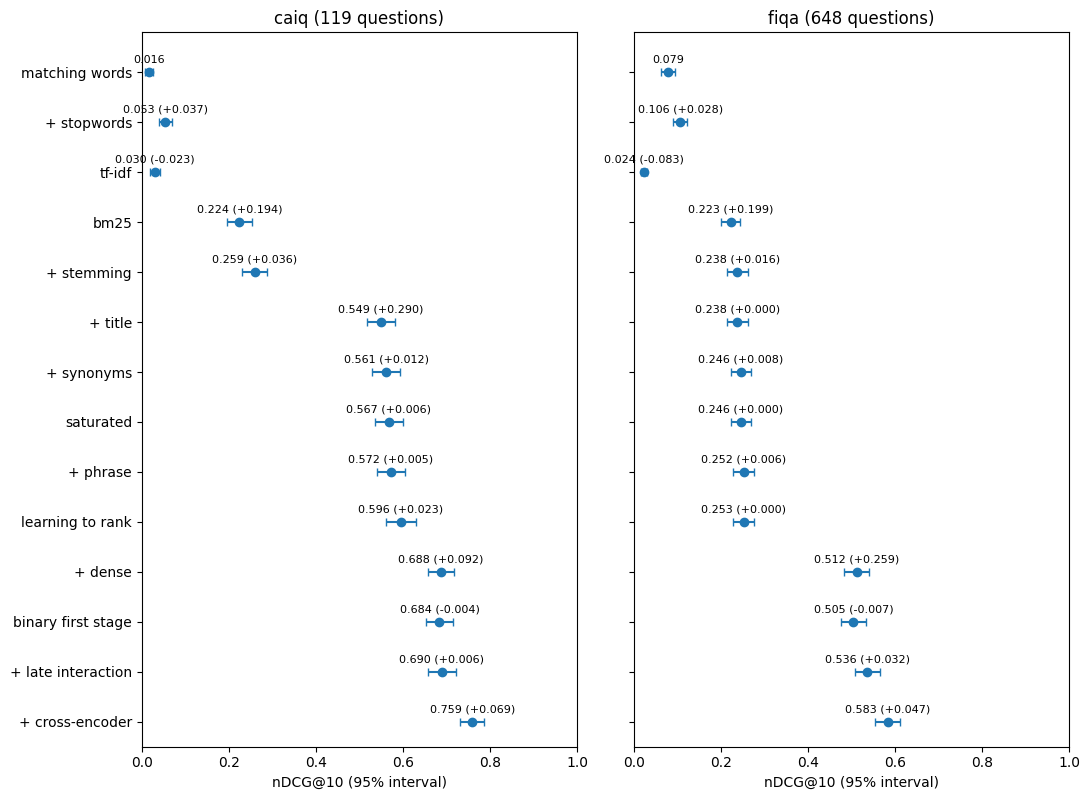

In [50]:
LAM_CE = {ds.name: max(lams, key=lambda lam: np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], reranked(ds, lam, "voyage-rerank-3")).values())))
          for ds in DATASETS}  # read off the curves above
print(LAM_CE)
for ds in DATASETS:
    runs[ds.name]["+ cross-encoder"] = lab.evaluate_top(ds, TOP20[ds.name], reranked(ds, LAM_CE[ds.name], "voyage-rerank-3"))
lab.plot_ladder(runs);

In [51]:
gain = {q: runs["caiq"]["+ cross-encoder"][q] - runs["caiq"]["binary first stage"][q] for q in caiq.qids}
example = max(gain, key=gain.get)
lab.show(caiq, example, {"binary first stage": STEP5["caiq"],
                            "+ cross-encoder": lab.expand(caiq, TOP20["caiq"], reranked(caiq, LAM_CE["caiq"], "voyage-rerank-3"))})

q:present:IAM-06.1: For Present SpA: Is a user access provisioning process defined and implemented which authorizes, records, and communicates data and assets access changes?

binary first stage  nDCG@10 0.399
  1. [.] present:IAM-14.1 Present SpA — IAM-14.1: Are processes, procedures, and technical measures for authenticati…
  2. [.] present:IAM-16.1 Present SpA — IAM-16.1: Are processes, procedures, and technical measures to verify access…
  3. [1] present:IAM-10.1 Present SpA — IAM-10.1: Is an access process defined and implemented to ensure privileged …
  4. [.] present:HRS-02.1 Present SpA — HRS-02.1: Are policies and procedures for defining allowances and conditions…
  5. [1] present:CCC-04.1 Present SpA — CCC-04.1: Is the unauthorized addition, removal, update, and management of o…

+ cross-encoder  nDCG@10 0.753
  1. [1] fimil:IAM-06.1 Fimil — IAM-06.1: Is a user access provisioning process defined and implemented? Yes. Emai…
  2. [.] present:IAM-16.1 Present SpA — IAM-16.1: Ar

## 20. How sure are we?

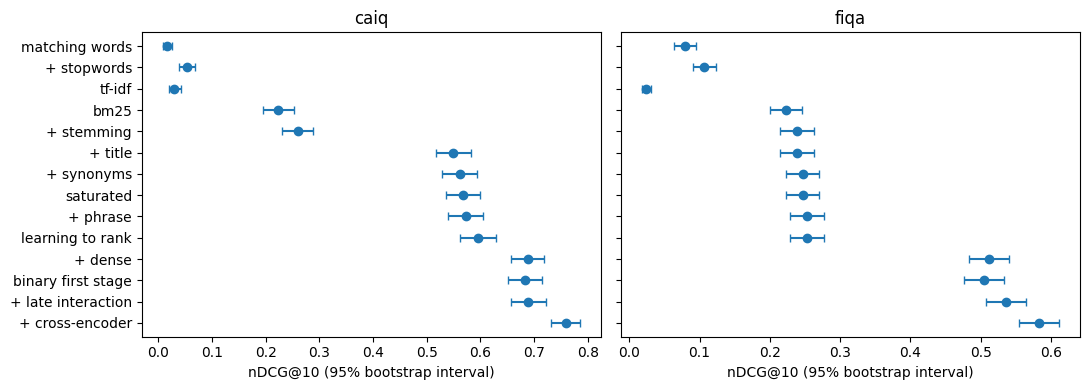

In [52]:
PER_Q = {ds.name: {step: np.array([r[q] for q in ds.qids]) for step, r in runs[ds.name].items()} for ds in DATASETS}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    steps = list(PER_Q[ds.name])
    for i, step in enumerate(steps):
        x = PER_Q[ds.name][step]
        lo, hi = lab.bootstrap(x)
        ax.errorbar(x.mean(), i, xerr=[[x.mean() - lo], [hi - x.mean()]], fmt="o", color="C0", capsize=3)
    ax.set_yticks(range(len(steps)), steps)
    ax.set_title(ds.name)
    ax.set_xlabel("nDCG@10 (95% bootstrap interval)")
axes[0].invert_yaxis()
fig.tight_layout()

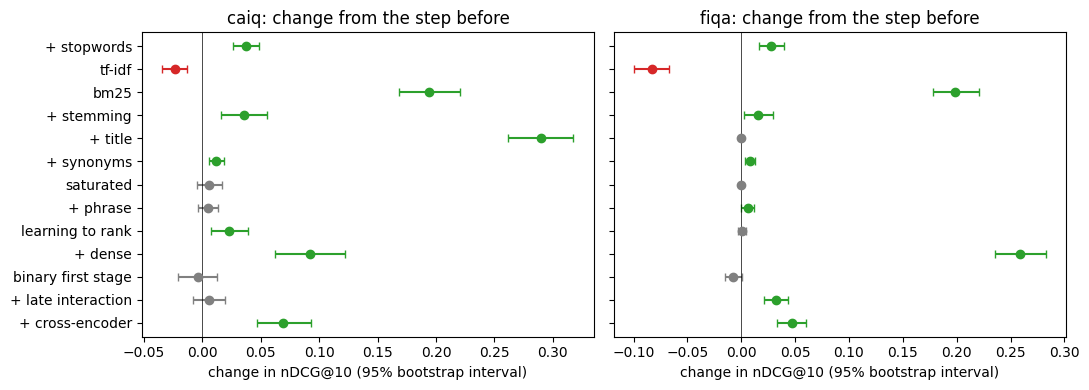

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    steps = list(PER_Q[ds.name])
    for i, (before, step) in enumerate(zip(steps, steps[1:])):
        d = PER_Q[ds.name][step] - PER_Q[ds.name][before]  # the same questions, before and after
        lo, hi = lab.bootstrap(d)
        color = "C2" if lo > 0 else "C3" if hi < 0 else "grey"
        ax.errorbar(d.mean(), i, xerr=[[d.mean() - lo], [hi - d.mean()]], fmt="o", color=color, capsize=3)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_yticks(range(len(steps) - 1), steps[1:])
    ax.set_title(f"{ds.name}: change from the step before")
    ax.set_xlabel("change in nDCG@10 (95% bootstrap interval)")
axes[0].invert_yaxis()
fig.tight_layout()

## 21. Debugging failing questions

In [54]:
FINAL = {ds.name: reranked(ds, LAM_CE[ds.name], "voyage-rerank-3") for ds in DATASETS}

for ds in DATASETS:
    print(f"{ds.name}: the 10 questions the final ranking does worst on")
    for q in sorted(ds.qids, key=lambda q: runs[ds.name]["+ cross-encoder"][q])[:10]:
        r = ds.qrow[q]
        cand = TOP20[ds.name][r]
        first = [k for k, i in enumerate(cand[np.argsort(-FINAL[ds.name][r], kind="stable")], 1) if ds.qrels[q].get(ds.ids[i], 0) > 0]
        verdict = f"first relevant at {first[0]} of 20" if first else "no relevant document among the 20 candidates"
        print(f"  {runs[ds.name]['+ cross-encoder'][q]:.2f}  {verdict:46s} {ds.queries[q][:80]}")

caiq: the 10 questions the final ranking does worst on
  0.00  no relevant document among the 20 candidates   For Octopus Deploy: Do you publish a list of all APIs available in the service a
  0.38  first relevant at 2 of 20                      For Realigned Technologies: Are your information security policies and procedure
  0.47  first relevant at 1 of 20                      For Present SpA: Are policies and procedures established, documented, approved, 
  0.51  first relevant at 1 of 20                      For Fimil: Is the classification and documentation of physical and logical asset
  0.52  first relevant at 1 of 20                      For Fimil: Are data center environmental control systems designed to monitor tem
  0.53  first relevant at 2 of 20                      For Realigned Technologies: Are all identified security, contractual, and regula
  0.56  first relevant at 2 of 20                      For Octopus Deploy: Can you provide a published procedure for exiting the 

In [55]:
worst = min(caiq.qids, key=lambda q: runs["caiq"]["+ cross-encoder"][q])
lab.show(caiq, worst, {"binary first stage": STEP5["caiq"], "+ cross-encoder": lab.expand(caiq, TOP20["caiq"], FINAL["caiq"])})

q:octopus:IPY-01.1: For Octopus Deploy: Do you publish a list of all APIs available in the service and indicate which are standard and which are customized?

binary first stage  nDCG@10 0.000
  1. [.] octopus:STA-07.4 Octopus Deploy — STA-07.4: Do you provide tenants with ongoing visibility and reporting of…
  2. [.] octopus:BCR-10.1 Octopus Deploy — BCR-10.1: Are policies and procedures established and made available for …
  3. [.] octopus:STA-02.1 Octopus Deploy — STA-02.1: Do you make security incident information available to all affe…
  4. [.] octopus:DCS-01.2 Octopus Deploy — DCS-01.2: Do you maintain a complete inventory of all of your critical as…
  5. [.] octopus:IVS-08.1 Octopus Deploy — IVS-08.1: For your SaaS or PaaS offering, do you provide tenants with sep…

+ cross-encoder  nDCG@10 0.000
  1. [.] octopus:BCR-10.1 Octopus Deploy — BCR-10.1: Are policies and procedures established and made available for …
  2. [.] octopus:DSI-03.1 Octopus Deploy — DSI-03.1: Do you provide 

## 22. Leaderboard

In [56]:
import json, re, urllib.error, urllib.request
from concurrent.futures import ThreadPoolExecutor

LAB = json.load(open(".lab.json"))  # written by: python3 lab.py connect URL TOKEN

def post(url, key, body):
    req = urllib.request.Request(url, json.dumps(body).encode(),
                                 {"Authorization": f"Bearer {key}", "Content-Type": "application/json"})
    try:
        with urllib.request.urlopen(req, timeout=120) as r:
            return json.load(r)
    except urllib.error.HTTPError as e:
        raise RuntimeError(f"{e.code}: {e.read().decode(errors='replace')}") from None

def embed(text):
    """The question's pplx vector from the lab: it must match the documents' vectors."""
    r = post(f"{LAB['url']}/v1/embeddings", LAB["token"], dict(model="pplx-embed", input=[text]))
    return np.array(r["data"][0]["embedding"], dtype=np.float32)[None]

In [57]:
DOC_BITS = {name: (d.mean(0), signs(d - d.mean(0))) for name, (d, _) in VEC.items()}

def search(ds, query, qid=None, k=5, mask=None, rerank=True):
    """The ladder for one new question: lexical + dense over the binary candidates, then Voyage on the top 20.
    qid hides what that question hides (its own answer); mask (one bool per document) searches only those documents;
    rerank=False stops before Voyage (the lab can rerank only its own datasets)."""
    one = lab.single(ds, query, qid)
    keep = np.ones(len(ds.ids), dtype=bool) if mask is None else np.asarray(mask)
    only = lambda s: np.where(keep, s, -np.inf)
    text = lab.bm25(one, ds.texts, idf_texts=ds.title_text, analyzer=ANALYZER)
    title = lab.bm25(one, ds.titles, idf_texts=ds.title_text, analyzer=ANALYZER)
    lexical = text / (S + text) + title / (S + title) + 0.2 * (0.5 * lab.phrase(one, ds.texts, ANALYZER) + lab.phrase(one, ds.titles, ANALYZER))
    q = embed(query)
    mean, bits = DOC_BITS[ds.name]
    n = min(20, len(ds.ids))
    cand = lab.candidates(one, [only(signs(q - mean) @ bits.T), only(text + title)], n)
    step5 = np.where(cand & keep, 4 * np.maximum(0, (q - mean) @ bits.T / np.sqrt(bits.shape[1])) + lexical, -np.inf)
    top = lab.topk(one, step5, n)
    top = top[:, np.isfinite(np.take_along_axis(step5, top, 1))[0]]
    if not rerank or top.shape[1] < 2:
        return top[0][:k]
    fused = minmax(np.take_along_axis(step5, top, 1)) + 4 * minmax(lab.rerank(one, top, "voyage-rerank-3"))
    return top[0][np.argsort(-fused[0])][:k]

def bm25_search(ds, query, qid=None, k=5):
    """Plain BM25 over the text."""
    one = lab.single(ds, query, qid)
    return lab.topk(one, lab.bm25(one, ds.texts), k)[0]

def hits(ds, rows):
    return "\n".join(f"{n}. [doc:{ds.ids[i]}] {ds.titles[i]}\n   {ds.texts[i][:300]}" for n, i in enumerate(rows, 1))

def read(ds, doc_id):
    i = ds.row.get(doc_id)
    return f"[doc:{doc_id}] {ds.titles[i]}\n{ds.texts[i][:4000]}" if i is not None else f"no document {doc_id}"

In [44]:
for label, fn in (("bm25", bm25_search), ("the ladder", search)):
    print(label, lab.submit(fiqa, fn, label))

bm25 {'score': 0.0551, 'best': 0.0551, 'rank': 1, 'of': 1}


the ladder {'score': 0.5156, 'best': 0.5156, 'rank': 1, 'of': 1}


## 23. A RAG agent from scratch

In [58]:
BASE_URL, API_KEY, MODEL = LAB["url"] + "/v1", LAB["token"], "claude-haiku-5-5"  # or any OpenAI-compatible provider

def chat(messages, tools=(), tool_choice="auto"):
    body = dict(model=MODEL, messages=messages, **(dict(tools=list(tools), tool_choice=tool_choice) if tools else {}))
    return post(f"{BASE_URL}/chat/completions", API_KEY, body)

reply = chat([dict(role="user", content="In one sentence: what does BM25 score?")])
print(reply["choices"][0]["message"]["content"])
print(reply["usage"])

BM25 scores how relevant a document is to a search query by combining the query terms' frequency in the document, weighted by inverse document frequency (rarer terms count more), with saturation and document-length normalization.
{'prompt_tokens': 22, 'completion_tokens': 66, 'total_tokens': 88, 'prompt_tokens_details': {'cached_tokens': 0}, 'usd': 3.5e-05}


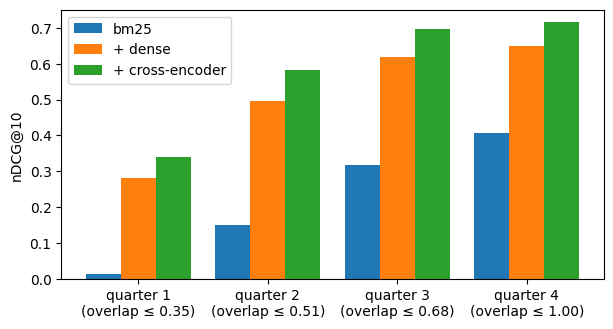

In [59]:
INDEX = lab.index(fiqa.texts)

def overlap(ds, qid):
    """How much of the question's wording (weighted by idf) its best relevant post contains."""
    weight = {t: INDEX.idf[INDEX.vocab[t]] for t in set(lab.tokenize(ds.queries[qid])) if t in INDEX.vocab}
    total = sum(weight.values()) or 1.0
    posts = [set(lab.tokenize(ds.texts[ds.row[d]])) for d, g in ds.qrels[qid].items() if g > 0 and d in ds.row]
    return max((sum(w for t, w in weight.items() if t in p) / total for p in posts), default=0.0)

OVERLAP = np.array([overlap(fiqa, q) for q in fiqa.qids])
quarter = np.digitize(OVERLAP, np.quantile(OVERLAP, [0.25, 0.5, 0.75]))
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, step in enumerate(("bm25", "+ dense", "+ cross-encoder")):
    ax.bar(np.arange(4) + 0.27 * (k - 1), [np.mean([runs["fiqa"][step][q] for q, b in zip(fiqa.qids, quarter) if b == j])
                                            for j in range(4)], 0.27, label=step)
ax.set_xticks(range(4), [f"quarter {j + 1}\n(overlap ≤ {OVERLAP[quarter == j].max():.2f})" for j in range(4)])
ax.set_ylabel("nDCG@10")
ax.legend()

In [60]:
HARD = sorted(np.random.default_rng(0).choice([q for q, b in zip(fiqa.qids, quarter) if b == 0], 40, replace=False))
qid = HARD[0]
print(fiqa.queries[qid], "\n")
for name, fn in (("bm25_search", bm25_search), ("search", search)):
    found = fn(fiqa, fiqa.queries[qid], qid)
    print(f"{name}: relevant {[fiqa.qrels[qid].get(fiqa.ids[i], 0) for i in found]}")
    print(hits(fiqa, found[:2]), "\n")


How does Walmart account their expired food 

bm25_search: relevant [0, 0, 0, 0, 0]
1. [doc:599998] 
   "Your argument comes down to ""he is presumed guilty until proven innocent"", a common injustice found in many authoritarian dictatorships and theocracies throughout history. Your argument seems based on the assumption that M. Armstrong is guilty without a requirement for any evidence that he did an
2. [doc:572490] 
   &gt;Why does minimum wage exist, if not to account for low skill jobs like those found in Walmart.  Minimum wage exists as a floor, the lowest possible amount someone can survive on. Paying anyone less would make survival impossible, in fact, many wal-mart employees are also on food stamps. 



search: relevant [1, 0, 0, 0, 0]
1. [doc:191649] 
   "Any business, like any household, has items that are wasted. Unlike a household, a business does keep track of all items that are unsellable. Depending on the reason for the item being unsellable they are accounted for differently. Items that can be returned to the manufacturer are done so, and the
2. [doc:599998] 
   "Your argument comes down to ""he is presumed guilty until proven innocent"", a common injustice found in many authoritarian dictatorships and theocracies throughout history. Your argument seems based on the assumption that M. Armstrong is guilty without a requirement for any evidence that he did an 



In [61]:
SYSTEM = ("You answer a financial question using the forum posts in the corpus. Answer concisely and practically. If "
          "the posts do not answer the question, say so. Search with a few focused queries, read the most promising posts, "
          "and cite every post you rely on as [doc:ID].")
TOOLS = [
    dict(type="function", function=dict(name="search", description="Search the forum posts. Returns the 5 best posts with a snippet each.",
                                        parameters=dict(type="object", properties=dict(query=dict(type="string")), required=["query"]))),
    dict(type="function", function=dict(name="read", description="Read one post in full.",
                                        parameters=dict(type="object", properties=dict(doc_id=dict(type="string")), required=["doc_id"]))),
]

def agent(ds, qid, search_with, budget=2, verbose=False):
    """The model answers question qid with up to `budget` turns of tool calls, then one turn with tools off."""
    messages = [dict(role="system", content=SYSTEM), dict(role="user", content=ds.queries[qid])]
    seen, searches, usd = set(), 0, 0.0
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have read."))
        reply = chat(messages, TOOLS, "auto" if turn < budget else "none")
        usd += reply["usage"].get("usd", 0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            name, args = call["function"]["name"], json.loads(call["function"]["arguments"])
            if verbose:
                print(f"{name}({args})")
            if name == "search":
                rows = search_with(ds, args["query"], qid)
                seen |= {ds.ids[i] for i in rows}
                searches += 1
                out = hits(ds, rows)
            else:
                out = read(ds, args["doc_id"])
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if not msg.get("tool_calls"):
            break
    return outcome(ds, qid, msg["content"] or "", seen, searches, usd)

def rag(ds, qid, search_with):
    """Classic RAG: one search with the question itself, the top 5 in the prompt, one answer."""
    rows = search_with(ds, ds.queries[qid], qid)
    reply = chat([dict(role="system", content=SYSTEM),
                  dict(role="user", content=f"{ds.queries[qid]}\n\nSearch results:\n{hits(ds, rows)}")])
    return outcome(ds, qid, reply["choices"][0]["message"]["content"] or "", {ds.ids[i] for i in rows}, 1,
                   reply["usage"].get("usd", 0))

def outcome(ds, qid, answer, seen, searches, usd):
    relevant = lambda d: ds.qrels[qid].get(d, 0) > 0
    cited = set(re.findall(r"\[doc:([^\]]+)\]", answer))
    return dict(answer=answer, searches=searches, usd=usd, seen_relevant=any(map(relevant, seen)),
                cited=len(cited), cited_relevant=sum(map(relevant, cited)))


In [42]:
run = agent(fiqa, qid, search, verbose=True)
print("\n" + run["answer"])
print("\njudge score", lab.grade(fiqa, qid, run["answer"])["score"])


search({'query': 'Walmart expired food accounting'})
search({'query': 'Walmart inventory shrink expired food write-off'})


read({'doc_id': '191649'})



The forum posts don't describe Walmart's actual accounting for expired food. The closest source is a general forum post, [doc:191649], which is not authoritative and doesn't mention Walmart. It says a business generally:

- Returns unsellable items that can go back to the manufacturer for credit.
- Tracks spoiled food, including scanning meat that has reached its "sell by" date into the computer, so the exact items and their value are recorded.
- Repurposes some items, such as turning bread into bread pudding, marking them down for quick sale, or donating them to charity, and tracks those too.
- Reflects any losses it can't recover in its prices.

For Walmart's specific treatment, such as how the write-off is booked or how it appears in financial statements, you would need its annual report (10-K) or inventory accounting policy. I didn't find those in the corpus.



judge score 0.5


In [43]:

def graded(args):
    method, search_with, qid = args
    run = method(fiqa, qid, search_with)
    g = lab.grade(fiqa, qid, run["answer"])
    return dict(run, score=g["score"], usd=run["usd"] + g["usd"])

with ThreadPoolExecutor(8) as pool:
    RUNS = {(method.__name__, fn.__name__): list(pool.map(graded, [(method, fn, q) for q in HARD]))
            for method in (rag, agent) for fn in (bm25_search, search)}

print(f"{'':24s}{'judge score':>13s}{'searches':>10s}{'relevant seen':>15s}{'cited relevant':>16s}{'cost':>8s}")
for (method, fn), rs in RUNS.items():
    cited = sum(r["cited"] for r in rs)
    print(f"{method + ', ' + fn:24s}{np.mean([r['score'] for r in rs]):13.3f}{np.mean([r['searches'] for r in rs]):10.1f}"
          f"{np.mean([r['seen_relevant'] for r in rs]):15.0%}{sum(r['cited_relevant'] for r in rs) / max(cited, 1):16.0%}"
          f"{sum(r['usd'] for r in rs):8.3f}")
for method in ("rag", "agent"):
    diff = np.array([b["score"] - a["score"] for a, b in zip(RUNS[method, "bm25_search"], RUNS[method, "search"])])
    print(f"{method}: search − bm25_search {diff.mean():+.3f} ± {1.96 * diff.std() / np.sqrt(len(diff)):.3f} (95%)")


                          judge score  searches  relevant seen  cited relevant    cost
rag, bm25_search                0.362       1.0             0%              0%   0.022
rag, search                     0.500       1.0            48%             13%   0.026
agent, bm25_search              0.450       2.6            12%              4%   0.046
agent, search                   0.550       2.2            48%             13%   0.044
rag: search − bm25_search +0.138 ± 0.077 (95%)
agent: search − bm25_search +0.100 ± 0.079 (95%)


## 24. Code mode

In [62]:
import builtins, io, sys, threading

class Meter(threading.local):
    calls = tokens = 0  # model calls and tokens of the run on this thread

METER = Meter()

def chat(messages, tools=(), tool_choice="auto"):
    """Section 16's chat, also counting calls and tokens in METER."""
    body = dict(model=MODEL, messages=messages, **(dict(tools=list(tools), tool_choice=tool_choice) if tools else {}))
    reply = post(f"{BASE_URL}/chat/completions", API_KEY, body)
    METER.calls += 1
    METER.tokens += reply["usage"]["total_tokens"]
    return reply

def metered(method, *args):
    """method(*args) and its model calls and tokens."""
    METER.calls = METER.tokens = 0
    run = method(*args)
    return dict(run, calls=METER.calls, tokens=METER.tokens)

SAFE = ("len", "range", "enumerate", "sorted", "min", "max", "sum", "set", "list", "dict", "str", "int", "float", "round",
        "zip", "any", "all")
MAX_LINES, MAX_OUTPUT = 100_000, 8_000

def run_code(code, functions):
    """Runs model-written code with `functions`, print and the SAFE builtins; returns what it printed and any error.
    This is NOT a security sandbox: Python's introspection reaches everything. It keeps a well-meaning model to our
    functions and stops runaway loops after MAX_LINES lines."""
    out, lines = io.StringIO(), 0

    def print_(*args, sep=" ", end="\n"):
        out.write(sep.join(map(str, args)) + end)

    def count(frame, event, arg):
        nonlocal lines
        lines += event == "line"
        if lines > MAX_LINES:
            raise RuntimeError(f"stopped after {MAX_LINES:,} lines")
        return count

    before = sys.gettrace()
    sys.settrace(lambda frame, event, arg: count if frame.f_code.co_filename == "<python>" else None)
    try:
        exec(compile(code, "<python>", "exec"), {"__builtins__": {n: getattr(builtins, n) for n in SAFE}, "print": print_, **functions})
    except Exception as e:
        print_(f"{type(e).__name__}: {e}")
    finally:
        sys.settrace(before)
    text = out.getvalue()
    return text if len(text) <= MAX_OUTPUT else text[:MAX_OUTPUT] + f"\n[cut at {MAX_OUTPUT:,} of {len(text):,} characters]"

print(run_code("for q in ('a', 'b'):\n    print(q, len(search(q)))\nimport os", dict(search=lambda q: [q] * 3)))
print(run_code("while True:\n    pass", {}))

a 3
b 3
ImportError: __import__ not found

RuntimeError: stopped after 100,000 lines



In [63]:
CODE_SYSTEM = ("You answer a financial question using the forum posts in the corpus. Answer concisely and practically. If the "
               "posts do not answer the question, say so. Your tool runs Python: in one program you can run several searches, "
               "print what you need and read the most promising posts. Cite every post you rely on as [doc:ID].")
CODE_TOOLS = [dict(type="function", function=dict(
    name="python",
    description="Run Python code. Available: search(query, k=5) -> list of {doc_id, title, snippet}, best first; "
                "read(doc_id) -> the post's text; print. Only what you print comes back (up to 8,000 characters). No imports; "
                f"builtins: {', '.join(SAFE)}.",
    parameters=dict(type="object", properties=dict(code=dict(type="string")), required=["code"])))]
MAX_SEARCHES = 15  # per question

def code_agent(ds, qid, search_with, budget=2, verbose=False):
    """Section 16's agent with one tool, python, that calls search and read."""
    messages = [dict(role="system", content=CODE_SYSTEM), dict(role="user", content=ds.queries[qid])]
    seen, searches, usd = set(), 0, 0.0

    def search_(query, k=5):
        nonlocal searches
        if searches >= MAX_SEARCHES:
            raise RuntimeError(f"no searches left ({MAX_SEARCHES} per question)")
        searches += 1
        rows = search_with(ds, str(query), qid, k=min(int(k), 20))
        seen.update(ds.ids[i] for i in rows)
        return [dict(doc_id=ds.ids[i], title=ds.titles[i], snippet=ds.texts[i][:300]) for i in rows]

    functions = dict(search=search_, read=lambda doc_id: read(ds, str(doc_id)))
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have read."))
        reply = chat(messages, CODE_TOOLS, "auto" if turn < budget else "none")
        usd += reply["usage"].get("usd", 0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            code = json.loads(call["function"]["arguments"]).get("code", "")
            out = run_code(code, functions)
            if verbose:
                print(f"--- code\n{code}\n--- output\n{out[:1500]}{' […]' if len(out) > 1500 else ''}")
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if not msg.get("tool_calls"):
            break
    return outcome(ds, qid, msg["content"] or "", seen, searches, usd)

In [52]:
run = code_agent(fiqa, HARD[1], search, verbose=True)
print(f"\n{fiqa.queries[HARD[1]]}\n\n{run['answer']}")
print("\njudge score", lab.grade(fiqa, HARD[1], run["answer"])["score"])

--- code
qs=["reporting income from online store","sales from online store taxes reporting","report capital gains online sales","Etsy eBay income reporting taxes"]
seen={}
for q in qs:
    for r in search(q,k=5):
        seen[r['doc_id']]=r
for d,r in seen.items():
    print(d,r['title'],'|',r['snippet'][:200])
--- output
28764  | You would report it as business income on Schedule C.  You may be able to take deductions against that income as well (home office, your computer, an android device, any advertising or promotional exp
584074  | There are no clear guidelines. If you are selling as individual, then what ever profit you make gets added to your overall income as you pay tax accordingly. This is true for sole proprietor or partne
11021  | You need to register as self-employed with HMRC (it is perfectly fine to be self-employed and employed by an employer at the same time, in exactly your kind of situation). Then, when the income arrive
313361  | "If this is truly hobby income (you

--- code
for d in ['28764','411825','9353','355959']:
    print(d, read(d)[:1200],'\n---')
--- output
28764 [doc:28764] 
You would report it as business income on Schedule C.  You may be able to take deductions against that income as well (home office, your computer, an android device, any advertising or promotional expenses, etc.) but you'll want to consult an accountant about that. Generally you can only take those kinds of deductions if you use the space or equipment exclusively for business use (not likely if it's just a hobby).  The IRS is pretty picky about that stuff. 
---
411825 [doc:411825] 
"In simple terms, it is a business operation when it becomes a   profit-making enterprise. It is a grey area, but there is a difference between selling   occasional personal items on eBay and selling for profit. I would imagine the sort of considerations HM Revenue & Customs would   take into account are the size of your turnover, the extent to which   you are both buying and selling, and 


Reporting financial gains from my online store

Your reporting depends on whether the store is a business or a hobby, and on the country. The forum posts I found are mostly US-focused, with one UK answer.

**If it's a business (profit-motivated, ongoing):** Report the net income on Schedule C in the US [doc:28764]. You can deduct expenses such as advertising and promotional costs, but the IRS expects business-only use for things like a home office or equipment [doc:28764]. In the UK, you register as self-employed with HMRC and enter the net earnings under "other income" [doc:411825], [doc:11021].

**If it's hobby income (no profit motive):** In the US, report it on Line 21 ("other income") of Form 1040 [doc:313361]. Hobby expenses are generally not deductible on Schedule A or elsewhere, so the income is taxed without offsetting them [doc:451020].

**If you're selling items for more than you paid:** The gain is taxable. Report it on Form 8949, which flows to Schedule D [doc:9353], [doc


judge score 0.5


In [53]:
def judged(method, qid):
    run = metered(method, fiqa, qid, search)
    return dict(run, score=lab.grade(fiqa, qid, run["answer"])["score"])

with ThreadPoolExecutor(8) as pool:
    CODE_RUNS = {m.__name__: list(pool.map(lambda q, m=m: judged(m, q), HARD)) for m in (agent, code_agent)}
print(f"{'':12s}{'judge score':>13s}{'searches':>10s}{'model calls':>13s}{'tokens':>9s}{'cost':>8s}")
for name, rs in CODE_RUNS.items():
    print(f"{name:12s}{np.mean([r['score'] for r in rs]):13.3f}{np.mean([r['searches'] for r in rs]):10.1f}"
          f"{np.mean([r['calls'] for r in rs]):13.1f}{np.mean([r['tokens'] for r in rs]):9,.0f}{sum(r['usd'] for r in rs):8.3f}")
diff = np.array([b["score"] - a["score"] for a, b in zip(CODE_RUNS["agent"], CODE_RUNS["code_agent"])])
lo, hi = lab.bootstrap(diff)
print(f"\ncode_agent − agent: {diff.mean():+.3f} (95% interval {lo:+.3f} to {hi:+.3f}) over {len(diff)} questions")

              judge score  searches  model calls   tokens    cost
agent               0.537       2.2          2.8    5,700   0.037
code_agent          0.625       3.1          2.8    5,464   0.036

code_agent − agent: +0.087 (95% interval +0.000 to +0.188) over 40 questions


## 25. Filters, sorting and counts

In [64]:
import operator
from collections import Counter

DEALS = lab.crm(n=600, seed=0)
CATEGORIES = lab.CATEGORIES
NUMBERS = ("amount_eur", "annual_revenue_eur", "employees", "probability")
print(f"{len(DEALS)} deals; fields: {', '.join(DEALS[0])}\n")
for d in DEALS[:3]:
    print(json.dumps(d, ensure_ascii=False), "\n")

600 deals; fields: deal_id, company, industry, country, stage, amount_eur, annual_revenue_eur, employees, probability, close_date, last_activity_date, owner, product, lead_source, notes

{"deal_id": "D0001", "company": "Elm Motors", "industry": "Construction", "country": "Denmark", "stage": "Closed won", "amount_eur": 56400.0, "annual_revenue_eur": 631880000.0, "employees": 5525, "probability": 1.0, "close_date": "2026-06-12", "last_activity_date": "2026-05-30", "owner": "Lukas Weber", "product": "Support Plus", "lead_source": "Webinar", "notes": "Elm Motors wants to consolidate reporting across its regional offices. Pipewise offered a 30% discount. Strong executive sponsor, low risk."} 

{"deal_id": "D0002", "company": "Lumen Logistics", "industry": "Media", "country": "Canada", "stage": "Closed lost", "amount_eur": 129900.0, "annual_revenue_eur": 129240000.0, "employees": 741, "probability": 0.0, "close_date": "2026-06-14", "last_activity_date": "2026-06-06", "owner": "Anna Schmidt",

In [65]:
VECS = lab.embeddings()  # precomputed with the data; anything else is embedded by the lab

def embed_many(texts):
    """Unit pplx vectors of texts, 16 per request; each text is embedded once."""
    new = list(dict.fromkeys(t for t in texts if t not in VECS))
    for a in range(0, len(new), 16):
        r = post(f"{LAB['url']}/v1/embeddings", LAB["token"], dict(model="pplx-embed", input=new[a:a + 16]))
        for t, e in zip(new[a:a + 16], sorted(r["data"], key=lambda e: e["index"])):
            v = np.array(e["embedding"], dtype=np.float32)
            VECS[t] = v / np.linalg.norm(v)
    return np.stack([VECS[t] for t in texts])

def index(name):
    """A dataset that `search` can search (lab.documents(name)): the documents and their pplx vectors, no questions."""
    ids, titles, texts = lab.documents(name)
    d = embed_many([f"{t}\n{x}" for t, x in zip(titles, texts)])
    VEC[name], DOC_BITS[name] = (d, None), (d.mean(0), signs(d - d.mean(0)))
    return lab.Dataset(name, list(ids), list(titles), list(texts), {}, {}, {})

CRM = index("crm")

def key(field, x):
    return float(x) if field in NUMBERS else str(x).lower()  # dates are YYYY-MM-DD, so they compare as text

def matches(deal, field, want):
    """want: a value, a list of values (any of them), or {"min": x, "max": y}, both ends included; text ignores case."""
    v = key(field, deal[field])
    if isinstance(want, dict):
        return all(op(v, key(field, want[end])) for end, op in (("min", operator.ge), ("max", operator.le)) if end in want)
    return v in {key(field, w) for w in (want if isinstance(want, list) else [want])}

def search_crm(query="", filters=None, sort_by=None, descending=True, fields=None, limit=10, group_by=None):
    """`search` on the deals, plus what their attributes allow: filters narrow the deals it searches, sort_by orders
    the results by a number or date, fields picks what comes back, group_by counts the deals per value. total is the
    number of deals that pass the filters; with a query, the results are the best matches among them."""
    filters = filters or {}
    unknown = [f for f in [*filters, sort_by, group_by, *(fields or [])] if f is not None and f not in DEALS[0]]
    if unknown:
        return dict(error=f"unknown fields {unknown}; the fields are {list(DEALS[0])}")
    mask = np.array([all(matches(d, f, w) for f, w in filters.items()) for d in DEALS])
    rows = list(search(CRM, query, k=50, mask=mask, rerank=False)) if query.strip() else list(np.flatnonzero(mask))
    if sort_by:
        rows.sort(key=lambda i: key(sort_by, DEALS[i][sort_by]), reverse=descending)
    keep = ["deal_id", *(fields or ["company", "industry", "country", "stage", "amount_eur", "owner"])]
    out = dict(total=int(mask.sum()), deals=[{f: DEALS[i][f] for f in keep} for i in rows[:min(int(limit), 50)]])
    if group_by:
        out["counts"] = dict(Counter(DEALS[i][group_by] for i in np.flatnonzero(mask)).most_common())
    return out

print(hits(CRM, search(CRM, "worried about security, budget frozen", rerank=False)[:3]), "\n")
print(search_crm(filters={"country": ["Finland", "Sweden"], "amount_eur": {"min": 20000}}, sort_by="amount_eur",
                 fields=["company", "country", "stage", "amount_eur"], limit=3, group_by="stage"))

1. [doc:D0387] Zenith Group
   Zenith Group is tightening data security after a breach. Budget freeze until the second quarter. industry: Education; country: Finland; stage: Contract sent; amount eur: 26400.0; annual revenue eur: 17390000.0; employees: 113; probability: 0.9; close date: 2026-12-24; last activity date: 2026-10-04;
2. [doc:D0486] Fjord Systems
   Fjord Systems wants to automate support ticket routing. Currently uses Pipewise and is unhappy with the pricing. Budget freeze until the second quarter. industry: Healthcare; country: United Kingdom; stage: Negotiation; amount eur: 108600.0; annual revenue eur: 1006650000.0; employees: 7640; probabi
3. [doc:D0278] Boreal Capital
   Boreal Capital needs an integration with SAP. Budget freeze until the second quarter. industry: Public sector; country: United Kingdom; stage: Closed won; amount eur: 50200.0; annual revenue eur: 20700000.0; employees: 233; probability: 1.0; close date: 2026-06-01; last activity date: 2026-05-28; ow 


In [66]:
VALUE_DS = index("crm-values")
VALUES = [tuple(i.split("=", 1)) for i in VALUE_DS.ids]
FIELD_DS = index("crm-fields")

def find_values(text, field=None, k=10):
    """The values of the category fields that best match text, e.g. "fintech" -> industry "Financial services"."""
    mask = None if field is None else np.array([f == field for f, _ in VALUES])
    return [dict(field=VALUES[i][0], value=VALUES[i][1]) for i in search(VALUE_DS, text, k=int(k), mask=mask, rerank=False)]

def find_fields(text, k=3):
    """The number and date fields that best match text, e.g. "biggest" -> amount_eur."""
    return [dict(field=FIELD_DS.ids[i], about=FIELD_DS.texts[i]) for i in search(FIELD_DS, text, k=int(k), rerank=False)]

for text in ("fintech", "the Nordics", "late stage", "Maria", "car makers"):
    print(f"{text!r:14} {[v['value'] for v in find_values(text, k=5)]}")
for text in ("biggest", "gone quiet", "headcount", "about to close"):
    print(f"{text!r:16} {[f['field'] for f in find_fields(text)]}")

'fintech'      ['Financial services', 'Education', 'Insurance', 'Analytics Suite', 'Support Plus']
'the Nordics'  ['Norway', 'Iceland', 'Denmark', 'Finland', 'Sweden']


'late stage'   ['Contract sent', 'Negotiation', 'Qualification', 'Closed lost', 'Discovery']
'Maria'        ['Maria Virtanen', 'Sofia Rossi', 'Anna Schmidt', 'Emma Johansson', 'Olivia Brown']


'car makers'   ['Automotive', 'Mikko Laine', 'Discovery', 'Maria Virtanen', 'Construction']
'biggest'        ['amount_eur', 'probability', 'annual_revenue_eur']
'gone quiet'     ['last_activity_date', 'employees', 'probability']


'headcount'      ['employees', 'amount_eur', 'annual_revenue_eur']
'about to close' ['close_date', 'probability', 'annual_revenue_eur']


In [67]:
CRM_SYSTEM = (f"You answer questions about our sales deals with the CRM search. Today is {lab.CRM_TODAY}. A deal is open "
              "until it is won or lost. End your answer with one line: DEALS: the comma-separated ids of the deals that answer "
              "the question (DEALS: none if there are none).")

def tool(name, description, required=(), **params):
    return dict(type="function", function=dict(name=name, description=description,
                                               parameters=dict(type="object", properties=params, required=list(required))))

PLAIN_SEARCH = tool("search", "Search the CRM's deals. Returns the 5 best deals with a snippet each.", ["query"],
                    query=dict(type="string"))
READ_DEAL = tool("read", "Read one deal in full.", ["doc_id"], doc_id=dict(type="string"))
ATTR_SEARCH = tool(
    "search",
    "Search the CRM's deals. Fields: deal_id, company, notes (text); industry, country, stage, owner, product, lead_source "
    "(categories); amount_eur, annual_revenue_eur, employees, probability (numbers); close_date, last_activity_date "
    "(dates, YYYY-MM-DD). Returns the number of deals passing the filters and the first `limit` of them.",
    query=dict(type="string", description="What to look for in the deals; empty: every deal that passes the filters."),
    filters=dict(type="object", description='{field: value | [values] | {"min": x, "max": y}}; exact values, any case; '
                                            "min and max are inclusive."),
    sort_by=dict(type="string", description="A number or date field."), descending=dict(type="boolean"),
    fields=dict(type="array", items=dict(type="string"), description="The fields to return."),
    limit=dict(type="integer", description="At most 50; default 10."),
    group_by=dict(type="string", description="A category field: also return the number of matching deals per value."))
FIND_VALUES = tool("find_values", "Find the exact values of the category fields (industry, country, stage, owner, product, "
                   "lead_source) that match a word or phrase.", ["text"], text=dict(type="string"),
                   field=dict(type="string", description="Only this field's values."), k=dict(type="integer"))
FIND_FIELDS = tool("find_fields", "Find the number and date fields that match a property, e.g. 'size of the deal'.", ["text"],
                   text=dict(type="string"), k=dict(type="integer"))
PLAIN = dict(search=lambda query: hits(CRM, search(CRM, query, rerank=False)), read=lambda doc_id: read(CRM, doc_id))
ATTR = dict(search=search_crm, find_values=find_values, find_fields=find_fields)

def crm_agent(question, tools, functions, budget=5, verbose=False):
    """The model answers with up to `budget` turns of tool calls, then one turn with tools off. It lists its deals in
    the last line, so it is judged on what it says it found."""
    messages = [dict(role="system", content=CRM_SYSTEM), dict(role="user", content=question)]
    usd, calls = 0.0, []
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have found."))
        reply = chat(messages, tools, "auto" if turn < budget else "none")
        usd += reply["usage"].get("usd", 0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            name, args = call["function"]["name"], json.loads(call["function"]["arguments"])
            try:
                out = functions[name](**args)
            except (KeyError, TypeError, ValueError) as e:
                out = dict(error=f"{type(e).__name__}: {e}")
            calls.append(name)
            if verbose:
                print(f"{name}({json.dumps(args, ensure_ascii=False)})\n  -> {str(out)[:400]}")
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out if isinstance(out, str) else json.dumps(out, ensure_ascii=False)))
        if not msg.get("tool_calls"):
            break
    answer = msg["content"] or ""
    last = re.findall(r"^\W*DEALS:(.*)$", answer, re.M)
    return dict(answer=answer, deals=set(re.findall(r"D\d{4}", last[-1])) if last else set(), calls=calls, usd=usd)

In [68]:
NORDICS = ["Norway", "Sweden", "Denmark", "Finland", "Iceland"]
OPEN = [s for s in lab.STAGES if not s.startswith("Closed")]
QUESTIONS = [  # (question, the search_crm call that answers it)
    ("Fintech deals in the Nordics that are in negotiation or have a contract out.",
     dict(filters=dict(industry="Financial services", country=NORDICS, stage=["Negotiation", "Contract sent"]))),
    ("Which 5 of Maria's open deals have gone quiet the longest?",
     dict(filters=dict(owner="Maria Virtanen", stage=OPEN), sort_by="last_activity_date", descending=False, limit=5)),
    ("Which deals did we lose in Germany this year?",
     dict(filters=dict(country="Germany", stage="Closed lost", close_date=dict(min="2026-01-01")))),
    ("Our three biggest wins with hospitals and clinics.",
     dict(filters=dict(industry="Healthcare", stage="Closed won"), sort_by="amount_eur", limit=3)),
    ("Open deals that came from trade shows and should close before December.",
     dict(filters=dict(lead_source="Trade show", stage=OPEN, close_date=dict(max="2026-11-30")))),
    ("Pharma companies with more than 2,000 staff that are still in our pipeline.",
     dict(filters=dict(industry="Pharmaceuticals", employees=dict(min=2001), stage=OPEN))),
    ("The five largest deals for our AI product in the DACH countries.",
     dict(filters=dict(product="AI Assistant", country=["Germany", "Austria", "Switzerland"]), sort_by="amount_eur", limit=5)),
    ("Which UK deals are at the proposal stage?", dict(filters=dict(country="United Kingdom", stage="Proposal"))),
    ("Jonas's deals over 30k that haven't got past qualification yet.",
     dict(filters=dict(owner="Jonas Berg", amount_eur=dict(min=30000), stage=["Prospecting", "Qualification"]))),
    ("Shops and online stores we won through referrals.",
     dict(filters=dict(industry=["Retail", "E-commerce"], lead_source="Referral", stage="Closed won"))),
    ("The 4 deals in Japan or Singapore with the most recent contact.",
     dict(filters=dict(country=["Japan", "Singapore"]), sort_by="last_activity_date", limit=4)),
    ("Which deals with companies making over a billion a year did we lose?",
     dict(filters=dict(annual_revenue_eur=dict(min=1e9), stage="Closed lost"))),
    ("Which of Anna's deals close in the first quarter of 2027?",
     dict(filters=dict(owner="Anna Schmidt", close_date=dict(min="2027-01-01", max="2027-03-31")))),
    ("The three smallest open deals with government customers.",
     dict(filters=dict(industry="Public sector", stage=OPEN), sort_by="amount_eur", descending=False, limit=3)),
    ("Telco deals that came in through our webinars.", dict(filters=dict(industry="Telecommunications", lead_source="Webinar"))),
    ("Open energy deals where nobody has talked to the customer since the start of September.",
     dict(filters=dict(industry="Energy", stage=OPEN, last_activity_date=dict(max="2026-08-31")))),
    ("What's our biggest open deal in Finland?", dict(filters=dict(country="Finland", stage=OPEN), sort_by="amount_eur", limit=1)),
    ("Which banks and insurers in France have we had deals with?",
     dict(filters=dict(industry=["Financial services", "Insurance"], country="France"))),
    ("Car makers with deals over 100k.", dict(filters=dict(industry="Automotive", amount_eur=dict(min=100000)))),
    ("Small companies (under 50 people) we won in the Benelux.",
     dict(filters=dict(employees=dict(max=49), stage="Closed won", country=["Netherlands", "Belgium", "Luxembourg"]))),
]
GOLD = []
for q, call in QUESTIONS:
    r = search_crm(**{"limit": 50, **call})
    assert "limit" in call or r["total"] <= 50
    GOLD.append({d["deal_id"] for d in r["deals"]})
print("gold deals per question:", [len(g) for g in GOLD])

gold deals per question: [1, 5, 9, 3, 13, 3, 5, 4, 6, 2, 4, 1, 11, 3, 4, 3, 1, 2, 4, 2]


In [ ]:
CONDITIONS = {"search": ([PLAIN_SEARCH, READ_DEAL], PLAIN), "search + attributes": ([ATTR_SEARCH], ATTR),
              "+ value and field search": ([ATTR_SEARCH, FIND_VALUES, FIND_FIELDS], ATTR)}
with ThreadPoolExecutor(8) as pool:
    CRM_RUNS = {c: list(pool.map(lambda q, t=t, f=f: crm_agent(q, t, f), [q for q, _ in QUESTIONS]))
                for c, (t, f) in CONDITIONS.items()}
EXACT = {c: np.array([r["deals"] == g for r, g in zip(rs, GOLD)], dtype=float) for c, rs in CRM_RUNS.items()}
JACCARD = {c: np.array([len(r["deals"] & g) / max(len(r["deals"] | g), 1) for r, g in zip(rs, GOLD)]) for c, rs in CRM_RUNS.items()}
print(f"{'':28s}{'exact set':>11s}{'Jaccard':>9s}{'tool calls':>12s}{'cost':>8s}")
for c, rs in CRM_RUNS.items():
    lo, hi = lab.bootstrap(JACCARD[c])
    print(f"{c:28s}{EXACT[c].mean():11.0%}{JACCARD[c].mean():9.2f}{np.mean([len(r['calls']) for r in rs]):12.1f}"
          f"{sum(r['usd'] for r in rs):8.3f}   Jaccard 95% interval {lo:.2f} to {hi:.2f}")

In [ ]:
print("exact set:", " | ".join(CONDITIONS))
for q, *rs in zip([q for q, _ in QUESTIONS], *CRM_RUNS.values()):
    g = GOLD[[x for x, _ in QUESTIONS].index(q)]
    print("  ".join("✓" if r["deals"] == g else "✗" for r in rs), q)

In [ ]:
run = crm_agent("How are our customers in Norway doing?", [ATTR_SEARCH, FIND_VALUES, FIND_FIELDS], ATTR, verbose=True)
print("\n" + run["answer"])
print(f"\ncost {run['usd']:.4f}")

## 26. Tool search

bm25      recall@5 0.80  nDCG@5 0.70
dense     recall@5 0.95  nDCG@5 0.84
ladder    recall@5 0.97  nDCG@5 0.80


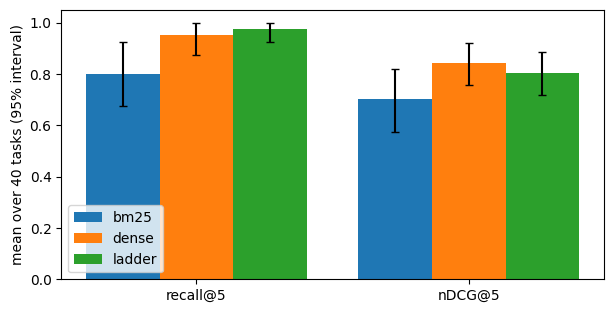

In [69]:
CATALOG = lab.tool_catalog()
TOOL_NAMES = [t["function"]["name"] for t in CATALOG]
TOOLS_DS = index("tools")
TASKS = [task for task, _ in lab.TOOL_TASKS]
embed_many(TASKS)  # one batch of requests instead of one per task

def find_tools(how, query, k=5):
    """The k best tools for query: bm25 alone, dense alone, or the ladder's first stage (search without reranking)."""
    if how == "bm25":
        return bm25_search(TOOLS_DS, query, k=k)
    if how == "dense":
        return np.argsort(-(VEC["tools"][0] @ embed_many([query])[0]), kind="stable")[:k]
    return search(TOOLS_DS, query, k=k, rerank=False)

def rank_of(rows, i):
    return list(rows).index(i) + 1 if i in list(rows) else 99

RANKS = {how: np.array([rank_of(find_tools(how, task, 20), TOOL_NAMES.index(wanted)) for task, wanted in lab.TOOL_TASKS])
         for how in ("bm25", "dense", "ladder")}
METRICS = {how: {"recall@5": (r <= 5).astype(float), "nDCG@5": np.where(r <= 5, 1 / np.log2(r + 1), 0.0)}
           for how, r in RANKS.items()}  # one relevant tool: its gain at rank r is 1 / log2(r + 1)
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, (how, m) in enumerate(METRICS.items()):
    means = [x.mean() for x in m.values()]
    lo, hi = np.array([lab.bootstrap(x) for x in m.values()]).T
    ax.bar(np.arange(2) + 0.27 * (k - 1), means, 0.27, yerr=[np.array(means) - lo, hi - np.array(means)], capsize=3, label=how)
    print(f"{how:8s}" + "".join(f"  {name} {x.mean():.2f}" for name, x in m.items()))
ax.set_xticks(range(2), list(METRICS["bm25"]))
ax.set_ylabel(f"mean over {len(TASKS)} tasks (95% interval)")
ax.set_ylim(0, 1.05)
ax.legend()

In [70]:
print("the ladder's misses:")
for (task, wanted), r in zip(lab.TOOL_TASKS, RANKS["ladder"]):
    if r > 5:
        print(f"  {task}\n    wanted {wanted} (rank {r}); top 3: {[TOOL_NAMES[i] for i in find_tools('ladder', task, 3)]}")

the ladder's misses:


  Let Mikko know privately that the build is green.
    wanted send_direct_message (rank 15); top 3: ['rollback_deployment', 'pin_chat_message', 'restart_service']


In [64]:
TOOL_SYSTEM = ("You are a workplace assistant with a catalog of about 60 tools. You start with search_tools only: describe what "
               "you need, and the tools it finds become callable on your next turn. Do the request with the right tool; do not "
               "ask questions, fill in reasonable values for missing details.")
SEARCH_TOOLS = tool("search_tools", "Find tools in the catalog by describing what you want to do. Returns the 5 best tools; "
                    "they become callable on your next turn.", ["query"], query=dict(type="string"))
SCHEMA = dict(zip(TOOL_NAMES, CATALOG))
BEST = max(METRICS, key=lambda how: METRICS[how]["nDCG@5"].mean())

def tool_agent(task, budget=4, verbose=False):
    """The model starts with search_tools (BEST's ranking); each turn's searches replace the tools offered before (the
    lab allows 8 per call). The catalog's tools do nothing and answer {"ok": true}."""
    messages = [dict(role="system", content=TOOL_SYSTEM), dict(role="user", content=task)]
    offered, called, searches, usd = [], [], 0, 0.0
    for turn in range(budget):
        reply = chat(messages, [SEARCH_TOOLS, *offered])
        usd += reply["usage"].get("usd", 0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        found = []
        for call in msg.get("tool_calls") or []:
            name, args = call["function"]["name"], json.loads(call["function"]["arguments"])
            if name == "search_tools":
                searches += 1
                found += [TOOL_NAMES[i] for i in find_tools(BEST, args["query"])]
                out = json.dumps([SCHEMA[n]["function"] for n in found[-5:]])
            else:
                called.append(name)
                out = json.dumps(dict(ok=True))
            if verbose:
                print(f"{name}({json.dumps(args)})" + (f"\n  -> {found[-5:]}" if name == "search_tools" else ""))
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if found:
            offered = [SCHEMA[n] for n in list(dict.fromkeys(found))[:7]]
        if not msg.get("tool_calls"):
            break
    return dict(called=called, searches=searches, usd=usd)

print(lab.TOOL_TASKS[3][0])
print(tool_agent(lab.TOOL_TASKS[3][0], verbose=True))

In [65]:
DEMO = lab.TOOL_TASKS[::4]
with ThreadPoolExecutor(8) as pool:
    TOOL_RUNS = list(pool.map(lambda task: tool_agent(task[0]), DEMO))
for (task, wanted), r in zip(DEMO, TOOL_RUNS):
    print(f"{'✓' if r['called'][:1] == [wanted] else '✗'} {task}\n    wanted {wanted}; called {r['called']}")
print(f"\nfirst call the right tool: {np.mean([r['called'][:1] == [t] for (_, t), r in zip(DEMO, TOOL_RUNS)]):.0%}; "
      f"searches per task {np.mean([r['searches'] for r in TOOL_RUNS]):.1f}; cost {sum(r['usd'] for r in TOOL_RUNS):.3f}")

✓ Book the Fjord room tomorrow from 14 to 15 for our design review.
    wanted schedule_meeting_room; called ['schedule_meeting_room']
✗ Write back to Tom's last email and tell him Thursday works.
    wanted reply_to_email; called ['search_email', 'search_email', 'search_email']
✓ Let Mikko know privately that the build is green.
    wanted send_direct_message; called ['send_direct_message']
✓ Mark ticket 4812 as solved.
    wanted update_ticket_status; called ['update_ticket_status']
✗ I need the onboarding guide as a PDF to send to a contractor.
    wanted export_document_pdf; called ['search_wiki', 'search_wiki']
✓ Elias starts with us on 3 November; get his paperwork and laptop going.
    wanted start_onboarding; called ['start_onboarding']
✗ Here's my taxi receipt from the client visit, 38 euros.
    wanted submit_expense_report; called []
✓ Ship version 2.14 of the billing service to production.
    wanted deploy_service; called ['deploy_service']
✓ The whole site is down, open a